# Benchmark P3, seed 42 — frozen PneuNet E5 vs full fine-tuning pretrained backbones

**Tidak menjalankan training notebook lama.** Notebook ini membaca **definisi terpilih saja** dari `PneuNet_E5_3Level_Segmentation_Ablation_FIXED.ipynb`, mengaudit dataset/mask/cache dan memuat checkpoint E5 `unet_resnet34__mask__P3__seed_42/best.pt` tanpa retraining. Head patologis RSNA dibuang; ketiga pretrained backbone memakai **head Linear biner baru** dan seluruh bobot backbone di-fine-tune.

Pipeline bersama: CXR asli → mask **cached pretrained U-Net ResNet34** → CLAHE pada citra → hard mask → letterbox 224×224 → augmentasi **statis train-only** 50% original / 25% rotasi ±15° / 25% Gaussian σ 0,5–1,5. Label NORMAL=0, PNEUMONIA=1. Split tetap 4.646 / 586 / 624. Val/test tidak diaugmentasi. Penetapan augmentasi dibandingkan dengan CSV sumber; mask tidak dibuat ulang.

| Model | Input setelah P3 | Binary head / training |
|---|---|---|
| PneuNet E5 P3 | grayscale float32 0–255, **tanpa /255** | Checkpoint seed 42; frozen untuk evaluasi klasifikasi |
| DenseNet121-RSNA | grayscale → `[-1024,1024]` | Pretrained **features**, Linear 1024→1 baru; full fine-tune |
| RAD-DINO ViT-B/14 | RGB grayscale ×1/255, mean 0.5307, std 0.2583 | CLS Linear 768→1 baru; full fine-tune |
| DINOv3 ViT-L/16 | RGB grayscale ×1/255, mean/std checkpoint | CLS Linear 1024→1 baru; full fine-tune + gradient checkpointing |

**Geometri tetap 224.** RAD-DINO default processor memakai 518; benchmark ini sengaja menonaktifkan resize/crop kedua, memakai interpolasi positional embeddings pada backbone dan mempertahankan **normalisasi resmi** checkpoint. Implementasi normalisasi diuji terhadap `AutoImageProcessor`/`xrv.datasets.normalize`, bukan diasumsikan. DINOv3 pada 224 menghasilkan 201 token: CLS + 4 register + 196 patch; RAD-DINO menghasilkan 257 token: CLS + 256 patch.

**FP32 murni:** batch fisik 32, tidak ada AMP/GradScaler/quantization/TF32/microbatch/gradient accumulation. `drop_last=False` mengikuti sumber: batch terakhir boleh berisi sisa sampel. Batas alokasi proses GPU 40 GiB; OOM dicatat dan **menghentikan** run tanpa mengganti batch. Gradient checkpointing DINOv3 diaktifkan sejak awal dan dicatat. Smoke fungsional pretrained memakai satu update Adam pada salinan model. Smoke fungsional E5 memakai backward ke input.

**Protokol fine-tune baru:** Adam lr 1e-4, β=(0.9,0.999), eps 1e-7, weight decay 0; maksimal 50 epoch, patience 7. Objective dan evaluasi benchmark: mean Weighted BCE yang sama dengan bobot dari **seluruh train split**. Ini protokol fine-tune yang dinyatakan, bukan klaim mereplikasi sejarah pelatihan pretrained/E5. E5 tetap memakai checkpoint historis pilihan validation BCE+L2 sumber; tidak dilakukan seleksi ulang atau retraining E5. Kurva E5 diberi label objective historisnya.

Best epoch pretrained dipilih dari **minimum validation weighted BCE**; model benchmark dipilih dari **validation Macro-F1**, dicatat sebelum evaluasi test benchmark. Threshold tetap 0.5. Test hanya untuk pelaporan. Semua checkpoint/CSV/grafik baru berada di `output_benchmark_P3_seed42/`; sumber dan checkpoint lama tidak ditimpa. Folder full run baru unik; `RESUME_RUN_DIRECTORY` dapat menunjuk run lama. Model dengan training.json + best.pt + history valid dilewati tanpa retraining; model parsial dilanjutkan dari last_training.pt (optimizer, epoch, RNG dan generator DataLoader). Run parsial lama tanpa state resume ditolak, tidak dimulai ulang diam-diam.

## Cara menjalankan

1. Gunakan kernel `Python (Pneumonia CUDA)`. Paket yang diuji dicatat pada `output_benchmark_P3_seed42/environment.json`. Bila perlu pasang dependency benchmark dengan interpreter kernel: `python -m pip install torchxrayvision==1.5.7 transformers==5.22.1 imageio scikit-image`. Tidak perlu mengubah PyTorch/CUDA yang sudah sesuai.
2. Konfigurasi awal menunjuk run yang sudah selesai. Semua flag eksekusi model berstatus False. Bagian VRAM menampilkan hasil tersimpan. Aktifkan `RUN_VRAM_BENCHMARK=True` untuk mengukur ulang dengan satu batch per fase.
3. Saat siap full benchmark, aktifkan ketiga flag full training/evaluation/attribution, lalu jalankan notebook baru ini. **Jangan menjalankan ulang notebook sumber.** Smoke gate harus PASS untuk seluruh model. Akses DINOv3 memerlukan akun HF yang telah disetujui; gunakan konfigurasi Hugging Face lokal, jangan menaruh token di notebook.
4. Untuk menampilkan kembali hasil tanpa training: `RUN_SMOKE=False`, `RUN_FULL_TRAINING=False`, isi `SAVED_BENCHMARK_RUN` di cell konfigurasi, lalu aktifkan flag evaluasi/atribusi yang diperlukan.

Latensi batch 1 dan 32 memakai CUDA events setelah warm-up, termasuk normalisasi checkpoint dan model, tanpa I/O/segmentasi/CLAHE/transfer host. Ini pengukuran pada GPU bersama, bukan janji performa dedicated. Tabel VRAM di bagian terakhir menampilkan inference, training-step, dan peak historis full training.

## Atribusi

CNN: Grad-CAM pada Residual Context terakhir E5 atau norm5 DenseNet. ViT: **positive gradient×activation patch-token attribution** pada norm1 sebelum attention block terakhir, bukan final patch tokens yang dapat terputus dari skor CLS. Bentuk token/grid diverifikasi, CLS/register dikeluarkan. Kedua kelas memakai skor −logit/+logit. Hooks dan mode model dipulihkan; probabilitas dicocokkan dengan inferensi biasa dan, pada hasil full, CSV prediksi. Heatmap relatif/terang bukan bukti model lebih baik atau ukuran akurasi segmentasi.

## Sumber resmi

- [TorchXRayVision](https://github.com/mlmed/torchxrayvision) dan [implementasi DenseNet](https://github.com/mlmed/torchxrayvision/blob/main/torchxrayvision/models.py).
- [RAD-DINO model card](https://huggingface.co/microsoft/rad-dino) dan [processor checkpoint](https://huggingface.co/microsoft/rad-dino/blob/main/preprocessor_config.json).
- [DINOv3 model card](https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m) dan [dokumentasi Transformers](https://huggingface.co/docs/transformers/model_doc/dinov3).

Checkpoint HF dipin ke commit dan SHA256 bobot dicatat. Semua angka performa klasifikasi full harus berasal dari evaluasi checkpoint fine-tuned; notebook tidak mengarang skor dari smoke.

### Resume dan pelaporan tanpa mengulang model lain

- Untuk melanjutkan run: isi `RESUME_RUN_DIRECTORY=OUTPUT_ROOT/'runs'/'nama_run'`, lalu aktifkan `RUN_FULL_TRAINING=True`. Model yang sudah selesai hanya divalidasi dan dilewati. Best checkpoint tetap dipilih dengan minimum validation loss; selection model tetap memakai validation Macro-F1 sebelum test.
- State resume tersimpan setelah tiap epoch validation. Interupsi di tengah epoch mengulang hanya epoch yang belum committed. Hasil dan failure log tidak dihapus. Jika best.pt/state resume tidak konsisten, run berhenti untuk pemeriksaan.
- Untuk menampilkan ulang hasil: `RUN_SMOKE=False`, `RUN_FULL_TRAINING=False`, isi `SAVED_BENCHMARK_RUN`, dan `RUN_FULL_EVALUATION=True`. Classification report dan confusion matrix TEST setiap model ditampilkan langsung, termasuk ketika hasil evaluasinya dipakai ulang.
- Cell 18 menggunakan hasil smoke aktual, bukan snapshot `validation.json` yang disediakan dari luar.


## 1. Konfigurasi aman, identitas E5, precision dan batas GPU

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, ast, hashlib, random, gc, time, copy, math, importlib.metadata
import numpy as np
import pandas as pd
import cv2
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, accuracy_score, precision_recall_fscore_support)

WORKSPACE = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p/'Datasets/chest_xray').is_dir())
SOURCE_NOTEBOOK = WORKSPACE/'PneuNet_E5_3Level_Segmentation_Ablation_FIXED.ipynb'
OUTPUT_ROOT = WORKSPACE/'output_benchmark_P3_seed42'
OLD_OUTPUT_ROOT = WORKSPACE/'output_pneunet_e5_segmentation_3level'
CACHE_ROOT = WORKSPACE/'tmp/pneunet_e5_segmentation_3level'
ROOT = WORKSPACE/'Datasets/chest_xray'
THIRD_PARTY = WORKSPACE/'third_party/CheXmask-Database'
HYBRID_WEIGHTS = THIRD_PARTY/'Weights/SegmentationModel/bestMSE.pt'
E5_DIRECTORY = OLD_OUTPUT_ROOT/'runs/full/unet_resnet34__mask__P3__seed_42'
SEED=42; IMG_SIZE=224; CLASS_NAMES=('NORMAL','PNEUMONIA'); CLASS_TO_ID={'NORMAL':0,'PNEUMONIA':1}
SPLITS=('train','val','test'); EXPECTED_COUNTS={'train':4646,'val':586,'test':624}
IMAGE_EXTENSIONS={'.jpeg','.jpg','.png','.bmp','.tif','.tiff','.webp'}
CPU_THREADS=2; ROI_MARGIN=.10; CLAHE_CLIP_LIMIT=2.5; CLAHE_TILE_GRID_SIZE=(8,8)
ROTATION_MAX_DEGREES=15.; GAUSSIAN_SIGMA_RANGE=(.5,1.5); AUGMENTATION_PROBS=(.5,.25,.25)
UNET_THRESHOLD=.20; MIN_MASK_AREA_FRAC=.03; MAX_MASK_AREA_FRAC=.85
E5_FLAGS={'detail':True,'fusion':False,'context':True,'normalized':True}
ABLATION_CONFIGS={'E5':dict(E5_FLAGS)}
PREPROCESS_PIPELINES={'P3':{'clahe':True,'augment':True,'normalize':False}}
VARIANT='unet_resnet34__mask'
MODEL_NAMES=('PneuNet_E5_P3','DenseNet121_RSNA','RAD_DINO','DINOv3_ViTL16')
HF_REPOS={'RAD_DINO':'microsoft/rad-dino','DINOv3_ViTL16':'facebook/dinov3-vitl16-pretrain-lvd1689m'}
# Pin exact commits rather than silently tracking updates to model weights/processors.
HF_REVISIONS = {'RAD_DINO':'110cbc18d5133582e320b43d53bf5c44e410c936',
                'DINOv3_ViTL16':'ea8dc2863c51be0a264bab82070e3e8836b02d51'}
DEVICE=torch.device('cuda:0'); PIN_MEMORY=True
PHYSICAL_BATCH_SIZE=32; MEMORY_BUDGET_GIB=40.; THRESHOLD=.5
DINO_GRADIENT_CHECKPOINTING=True
# Weighted BCE is identical across benchmark evaluations; pretrained full fine-tuning
# uses Adam (all weights), with a declared common learning rate and no extra L2 penalty.
FINETUNE_CONFIG=dict(epochs=50,learning_rate=1e-4,beta_1=.9,beta_2=.999,epsilon=1e-7,
                     early_stopping_patience=7,weight_decay=0.,threshold=.5)
RUN_SMOKE=False
RUN_FULL_TRAINING=False
RESUME_RUN_DIRECTORY=None  # Existing OUTPUT_ROOT/'runs'/...; completed models are skipped.
SAVED_BENCHMARK_RUN=OUTPUT_ROOT/'runs'/'20261119_044615_013633'
RUN_VRAM_BENCHMARK=False  # Set True to remeasure one batch per phase.
RUN_FULL_EVALUATION=False
RUN_ATTRIBUTION=False
LATENCY_WARMUP=5; LATENCY_REPEATS=20
ERROR_SAMPLES_PER_TYPE=3
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RUN_ROOT=OUTPUT_ROOT/'runs'/RUN_ID
SMOKE_ROOT=OUTPUT_ROOT/'smoke'/RUN_ID
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
if not torch.cuda.is_available(): raise RuntimeError('CUDA required; no CPU training fallback.')
torch.cuda.set_device(DEVICE);torch.set_num_threads(CPU_THREADS);cv2.setNumThreads(CPU_THREADS)
torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=False
torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
torch.set_float32_matmul_precision('highest')
# Warn-only deterministic enforcement preserves official CUDA graph operations.
# Non-deterministic ops, if encountered, are recorded as warnings rather than claiming bitwise determinism.
torch.use_deterministic_algorithms(True,warn_only=True)
torch.cuda.set_per_process_memory_fraction(min(1.,MEMORY_BUDGET_GIB*1024**3/torch.cuda.get_device_properties(DEVICE).total_memory),DEVICE)

def benchmark_seed(seed=SEED):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)

def write_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+'.tmp')
    temporary.write_text(json.dumps(value,indent=2,default=str)+'\n');temporary.replace(path)

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for part in iter(lambda:f.read(2**20),b''):h.update(part)
    return h.hexdigest()

E5_INFO=json.loads((E5_DIRECTORY/'result.json').read_text())
TRAIN_CONFIG=dict(E5_INFO['config']) # only for reconstructing the exact frozen E5 architecture
SOURCE_FINGERPRINT=E5_INFO['source_fingerprint']
ARCH_VERSION=E5_INFO['architecture_version']
assert E5_INFO['experiment_id']=='unet_resnet34__mask__P3' and E5_INFO['seed']==42
assert E5_INFO['mode']=='full' and E5_INFO['status']=='COMPLETE'
E5_CHECKPOINT_SHA256=sha256_file(E5_DIRECTORY/'best.pt')
benchmark_seed()
print('CUDA:',torch.cuda.get_device_name(DEVICE),'| FP32 only | batch',PHYSICAL_BATCH_SIZE)
print('Output:',OUTPUT_ROOT,'| Full training:',RUN_FULL_TRAINING)


CUDA: NVIDIA A100-SXM4-80GB | FP32 only | batch 32
Output: /home/arsyadmuhammad/AI Project/Pneumonia/output_benchmark_P3_seed42 | Full training: False


## 2. Definisi sumber yang diizinkan, dataset, mask/cache read-only, dan audit P3

In [2]:
# Import only explicitly whitelisted DEFINITIONS. Never execute source configuration,
# old mask-generation loops, run_one(), training_suite(), or old evaluation cells.
SOURCE_SHA256=sha256_file(SOURCE_NOTEBOOK)
_source=json.loads(SOURCE_NOTEBOOK.read_text())
_allowed=set('hash_file read_gray mask_dir mask_path mask_provenance validate_mask get_mask require_masks apply_clahe letterbox gaussian_blur rotate_image augmentation_counts make_augmentation_plan_3level box_from_mask transformed_source processed_image_uint8 get_padding_mask cache_variant_paths E5ConditionDataset GrayToRGB SamePadConv2d ConvBNReLU SEBlock ConcatenateChannels DepthwiseSeparableBlock LearnableSpatialPooling initialize_pneunet PneuNet BasicResidualBlock ResidualBottleneckFusion reset_model_state ConfigurableLearnableSpatialPooling PneuNetAblation build_ablation build_pneunet'.split())
_found={}
for _cell in _source['cells']:
    if _cell['cell_type']!='code':continue
    for _node in ast.parse(''.join(_cell['source'])).body:
        if isinstance(_node,(ast.FunctionDef,ast.ClassDef)) and _node.name in _allowed:
            if _node.name in _found:raise RuntimeError('Ambiguous source definition: '+_node.name)
            _found[_node.name]=ast.dump(_node,include_attributes=False)
            exec(compile(ast.Module(body=[_node],type_ignores=[]),str(SOURCE_NOTEBOOK),'exec'),globals())
assert set(_found)==_allowed
set_seed=benchmark_seed # source model builder uses this public seed helper
rows=[]
for split in SPLITS:
    for label in CLASS_NAMES:
        for path in sorted((ROOT/split/label).rglob('*')):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append(dict(path=str(path.resolve()),split=split,label=label,y=CLASS_TO_ID[label],relpath=str(path.relative_to(ROOT))))
df=pd.DataFrame(rows)
assert df.path.is_unique
for split,count in EXPECTED_COUNTS.items():assert int((df.split==split).sum())==count
df['file_size']=[Path(p).stat().st_size for p in df.path]
df['mtime_ns']=[Path(p).stat().st_mtime_ns for p in df.path]
CURRENT_SOURCE_FINGERPRINT=hashlib.sha256(df[['relpath','split','y','file_size','mtime_ns']].to_json(orient='records').encode()).hexdigest()
if CURRENT_SOURCE_FINGERPRINT!=SOURCE_FINGERPRINT:
    raise RuntimeError('Dataset fingerprint differs from E5 reference; do not bypass or silently change split.')
assert mask_provenance('unet_resnet34')==E5_INFO['mask_provenance']
require_masks('unet_resnet34',range(len(df)))
augmentation_plan=make_augmentation_plan_3level(df,seed=42)
# Compare the full static assignment, not just its random seed.
_original_plan=pd.read_csv(OLD_OUTPUT_ROOT/'static_augmentation_plan.csv')
pd.testing.assert_frame_equal(augmentation_plan.reset_index(drop=True),_original_plan.reset_index(drop=True),check_dtype=False)
assert (augmentation_plan.loc[df.split!='train','aug_mode']==0).all()

def ensure_variant_cache(variant):
    """Read-only reuse: never regenerate or overwrite a legacy preprocessing cache."""
    folder,raw_path,clahe_path,meta_path=cache_variant_paths(variant)
    if not all(p.is_file() for p in (raw_path,clahe_path,meta_path)):
        raise FileNotFoundError(f'Existing source cache missing: {folder}; build via the original approved pipeline first.')
    meta=json.loads(meta_path.read_text())
    assert meta['fingerprint']==SOURCE_FINGERPRINT and meta['variant']==variant
    assert meta['mask_provenance']==mask_provenance('unet_resnet34')
    assert meta['clahe_clip']==CLAHE_CLIP_LIMIT and tuple(meta['clahe_grid'])==CLAHE_TILE_GRID_SIZE
    arrays=(np.load(raw_path,mmap_mode='r'),np.load(clahe_path,mmap_mode='r'))
    assert all(a.shape==(5856,224,224) and a.dtype==np.uint8 for a in arrays)
    return arrays

DATASETS={split:E5ConditionDataset(VARIANT,'P3',df.index[df.split==split],use_cache=True) for split in SPLITS}
CLASS_COUNTS=np.bincount(df.loc[df.split=='train','y'],minlength=2)
CLASS_WEIGHTS=len(DATASETS['train'])/(2*CLASS_COUNTS.astype(np.float64))
np.testing.assert_allclose(CLASS_WEIGHTS,E5_INFO['class_weights'])

def loader(split,shuffle=False,subset=None):
    dataset=DATASETS[split] if subset is None else torch.utils.data.Subset(DATASETS[split],list(subset))
    return DataLoader(dataset,batch_size=32,shuffle=shuffle,num_workers=0,pin_memory=True,
                      drop_last=False,generator=torch.Generator().manual_seed(42))

def smoke_loader():
    local_labels=DATASETS['train'].labels.astype(int)
    indexes=np.concatenate([np.flatnonzero(local_labels==c)[:16] for c in (0,1)])
    assert len(indexes)==32
    return loader('train',subset=indexes)

# Validate true source masking/CLAHE/letterbox, and all three train augmentation modes.
_checked=[]
for mode in (0,1,2):
    candidates=augmentation_plan.index[(df.split=='train')&(augmentation_plan.aug_mode==mode)]
    _checked.append(int(candidates[0]))
_checked += [int(df.index[df.split==s][0]) for s in ('val','test')]
for index in _checked:
    raw=processed_image_uint8(VARIANT,index,True)
    row=augmentation_plan.iloc[index]
    if row.split=='train' and row.aug_mode==1:raw=rotate_image(raw,row.rotation_degrees)
    elif row.split=='train' and row.aug_mode==2:raw=gaussian_blur(raw,row.gaussian_sigma)
    local=int(np.flatnonzero(DATASETS[row.split].source_indices==index)[0])
    actual,label=DATASETS[row.split][local]
    np.testing.assert_array_equal(actual.numpy()[0],raw.astype(np.float32))
    assert actual.shape==(1,224,224) and actual.min()>=0 and actual.max()<=255
    assert int(label.item())==int(df.iloc[index].y)
PROTOCOL={'source_notebook_sha256':SOURCE_SHA256,'source_fingerprint':SOURCE_FINGERPRINT,
    'e5_checkpoint':str(E5_DIRECTORY/'best.pt'),'e5_checkpoint_sha256':E5_CHECKPOINT_SHA256,
    'mask_provenance':E5_INFO['mask_provenance'],'split_counts':EXPECTED_COUNTS,'class_weights':CLASS_WEIGHTS.tolist(),
    'augmentation_plan_sha256':hashlib.sha256(augmentation_plan.to_json(orient='records').encode()).hexdigest(),
    'batch':32,'precision':'float32','amp':False,'tf32':False,'resolution':224,'threshold':.5,
    'pretrained_finetune_config':FINETUNE_CONFIG,'e5_original_training_config':TRAIN_CONFIG,
    'e5_selection_note':'Frozen source best checkpoint, historically selected using weighted BCE + source L2; never retrained.',
    'geometry_note':'All models share 224 letterbox; official processor normalization only, no second resize/crop.',
    'source_definition_names':sorted(_found),'real_preprocessing_checks':len(_checked)}
write_json(OUTPUT_ROOT/'protocol.json',PROTOCOL)
print('Data/mask/P3 audits PASS; old source training was not executed.')
display(pd.crosstab(df.split,df.label));display(pd.crosstab(df.loc[df.split=='train','label'],augmentation_plan.loc[df.split=='train','aug_mode']))


Data/mask/P3 audits PASS; old source training was not executed.


label,NORMAL,PNEUMONIA
split,,
test,234,390
train,1198,3448
val,151,435


aug_mode,0,1,2
label,,,
NORMAL,599,300,299
PNEUMONIA,1724,862,862


## 3. Normalisasi resmi, pretrained backbones, dan binary heads

In [3]:
from transformers import AutoModel, AutoImageProcessor
from huggingface_hub import hf_hub_download

class InputNormalization(nn.Module):
    """Checkpoint-specific official intensity normalization, after shared P3."""
    def __init__(self,kind,processor=None):
        super().__init__();self.kind=kind
        if processor is not None:
            assert processor.do_rescale and processor.do_normalize
            self.factor=float(processor.rescale_factor)
            self.register_buffer('mean',torch.tensor(processor.image_mean,dtype=torch.float32).view(1,3,1,1))
            self.register_buffer('std',torch.tensor(processor.image_std,dtype=torch.float32).view(1,3,1,1))
            assert self.mean.shape==(1,3,1,1) and (self.std>0).all()
    def forward(self,x):
        if x.dtype!=torch.float32 or x.ndim!=4 or tuple(x.shape[1:])!=(1,224,224):
            raise ValueError(f'Expected float32 [B,1,224,224], got {x.dtype}/{x.shape}')
        if self.kind=='e5':return x
        if self.kind=='rsna':return ((x/255.)*2.-1.)*1024.
        return (x.repeat(1,3,1,1)*self.factor-self.mean)/self.std

class BenchmarkBinary(nn.Module):
    def __init__(self,name,load_pretrained=True):
        super().__init__();self.name=name;self.processor=None;self.metadata={}
        if name=='PneuNet_E5_P3':
            self.normalizer=InputNormalization('e5');self.backbone=build_pneunet(TRAIN_CONFIG)
            blob=torch.load(E5_DIRECTORY/'best.pt',map_location='cpu',weights_only=True)
            assert blob['experiment_id']=='unet_resnet34__mask__P3' and blob['seed']==42
            assert blob['architecture_version']==ARCH_VERSION and blob['config']==TRAIN_CONFIG
            self.backbone.load_state_dict(blob['state_dict'],strict=True)
            for p in self.parameters():p.requires_grad_(False)
            self.metadata={'checkpoint':str(E5_DIRECTORY/'best.pt'),'sha256':E5_CHECKPOINT_SHA256,'retrained':False}
        elif name=='DenseNet121_RSNA':
            import torchxrayvision as xrv
            # Use pretrained feature extractor only; discard ALL pathology outputs/thresholds.
            net=xrv.models.DenseNet(weights='densenet121-res224-rsna' if load_pretrained else None)
            width=net.classifier.in_features
            self.backbone=net.features;self.head=nn.Linear(width,1);self.normalizer=InputNormalization('rsna')
            weights_url=xrv.models.model_urls['densenet121-res224-rsna']['weights_url']
            self.metadata={'weights_id':'densenet121-res224-rsna','weights_url':weights_url,
                           'binary_head':'new Linear(1024,1); original pathology classifier discarded',
                           'normalization':'(raw255/255*2-1)*1024'}
            cache_file=Path(torch.hub.get_dir())/'checkpoints'/Path(weights_url).name
            # XRV maintains its own cache; hash the exact downloaded weights if present.
            candidates=list((Path.home()/'.torchxrayvision/models_data').glob(Path(weights_url).name))
            if cache_file.exists():candidates.append(cache_file)
            if candidates:self.metadata['weights_sha256']=sha256_file(candidates[0])
        else:
            repo=HF_REPOS[name];revision=HF_REVISIONS[name]
            self.processor=AutoImageProcessor.from_pretrained(repo,revision=revision)
            self.normalizer=InputNormalization('hf',self.processor)
            if not load_pretrained:raise ValueError('HF benchmark requires actual pretrained weights; no random fallback.')
            self.backbone=AutoModel.from_pretrained(repo,revision=revision,dtype=torch.float32,attn_implementation='sdpa')
            self.head=nn.Linear(self.backbone.config.hidden_size,1)
            if name=='DINOv3_ViTL16' and DINO_GRADIENT_CHECKPOINTING:
                self.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
            weights=hf_hub_download(repo,'model.safetensors',revision=revision)
            self.metadata={'repo_id':repo,'revision':revision,'weights_sha256':sha256_file(weights),
                'processor':self.processor.to_dict(),'geometry_override':'do_resize=False; do_center_crop=False; fixed shared 224 letterbox',
                'gradient_checkpointing':bool(getattr(self.backbone,'is_gradient_checkpointing',False)),
                'binary_head':'new CLS-token Linear(hidden_size,1)'}
            patch=int(self.backbone.config.patch_size)
            self.metadata.update(patch_size=patch,patch_grid=[224//patch,224//patch],
                                 register_tokens=int(getattr(self.backbone.config,'num_register_tokens',0)))
        self.float()
        if name!='PneuNet_E5_P3':
            for p in self.parameters():p.requires_grad_(True)
        self.metadata['parameters_total']=sum(p.numel() for p in self.parameters())
        self.metadata['parameters_trainable']=sum(p.numel() for p in self.parameters() if p.requires_grad)

    def forward(self,raw):
        x=self.normalizer(raw)
        if self.name=='PneuNet_E5_P3':return self.backbone(x)
        if self.name=='DenseNet121_RSNA':
            features=F.relu(self.backbone(x),inplace=False)
            return self.head(F.adaptive_avg_pool2d(features,1).flatten(1))
        sequence=self.backbone(pixel_values=x).last_hidden_state
        expected=1+int(getattr(self.backbone.config,'num_register_tokens',0))+(224//int(self.backbone.config.patch_size))**2
        if sequence.ndim!=3 or sequence.shape[1]!=expected:
            raise RuntimeError(f'Invalid ViT tokens: expected [B,{expected},D], got {sequence.shape}')
        return self.head(sequence[:,0])

    def attribution_layer(self):
        if self.name=='PneuNet_E5_P3':return self.backbone.get_submodule('context_refine.1.relu_out')
        if self.name=='DenseNet121_RSNA':return self.backbone.get_submodule('norm5')
        # Use the input to final attention, not final patch tokens disconnected from CLS.
        if self.name=='RAD_DINO':return self.backbone.encoder.layer[-1].norm1
        return self.backbone.model.layer[-1].norm1

def make_model(name):
    benchmark_seed()
    model=BenchmarkBinary(name).to(DEVICE)
    if not all(p.dtype==torch.float32 for p in model.parameters()):raise RuntimeError('Non-FP32 parameters')
    if name!='PneuNet_E5_P3' and not all(p.requires_grad for p in model.parameters()):raise RuntimeError('Backbone unexpectedly frozen')
    return model

def validate_normalization(model):
    raw=next(iter(smoke_loader()))[0][:2]
    normalized=model.normalizer(raw.to(DEVICE)).detach().cpu()
    if model.processor is not None:
        rgb=raw.repeat(1,3,1,1)
        expected=model.processor(images=[a.numpy() for a in rgb],return_tensors='pt',
            do_resize=False,do_center_crop=False,input_data_format='channels_first').pixel_values
        np.testing.assert_allclose(normalized.numpy(),expected.numpy(),rtol=1e-5,atol=2e-6)
        assert tuple(expected.shape)==(2,3,224,224)
    elif model.name=='DenseNet121_RSNA':
        import torchxrayvision as xrv
        expected=xrv.datasets.normalize(raw.numpy(),255)
        np.testing.assert_allclose(normalized.numpy(),expected,rtol=1e-6,atol=1e-4)
    else:np.testing.assert_array_equal(normalized.numpy(),raw.numpy())
    return {'status':'PASS','shape':list(normalized.shape),'geometry_changed':False}


## 4. Smoke fungsional batch 32, penanganan OOM, dan latensi

In [4]:
class BenchmarkOOM(RuntimeError):pass

def weighted_bce(logits,targets):
    logits=logits.reshape(-1);targets=targets.float().reshape(-1)
    if logits.shape!=targets.shape:raise ValueError('Logit/label shape mismatch')
    weights=torch.tensor(CLASS_WEIGHTS,dtype=torch.float32,device=logits.device)
    return (F.binary_cross_entropy_with_logits(logits,targets,reduction='none')*weights[targets.long()]).mean()

def make_finetune_optimizer(model):
    if model.name=='PneuNet_E5_P3':raise RuntimeError('E5 retraining is forbidden.')
    return torch.optim.Adam(model.parameters(),lr=FINETUNE_CONFIG['learning_rate'],
        betas=(FINETUNE_CONFIG['beta_1'],FINETUNE_CONFIG['beta_2']),eps=FINETUNE_CONFIG['epsilon'],
        weight_decay=FINETUNE_CONFIG['weight_decay'],foreach=False)

def gpu_peak():
    torch.cuda.synchronize(DEVICE)
    return {'peak_allocated_gib':torch.cuda.max_memory_allocated(DEVICE)/1024**3,
            'peak_reserved_gib':torch.cuda.max_memory_reserved(DEVICE)/1024**3,
            'free_gib':torch.cuda.mem_get_info(DEVICE)[0]/1024**3}

def measure_latency(model,batch_size):
    model.eval();raw=next(iter(smoke_loader()))[0][:batch_size].to(DEVICE)
    samples=[]
    with torch.no_grad():
        for _ in range(LATENCY_WARMUP):model(raw)
        torch.cuda.synchronize(DEVICE)
        for _ in range(LATENCY_REPEATS):
            start=torch.cuda.Event(enable_timing=True);end=torch.cuda.Event(enable_timing=True)
            start.record();model(raw);end.record();torch.cuda.synchronize(DEVICE)
            samples.append(start.elapsed_time(end))
    return {'batch':batch_size,'mean_ms_per_batch':float(np.mean(samples)),
            'std_ms_per_batch':float(np.std(samples,ddof=1)),'mean_ms_per_image':float(np.mean(samples)/batch_size),
            'includes':'checkpoint normalization + model; excludes mask/CLAHE/disk read and host transfer'}

def smoke_model(name):
    directory=SMOKE_ROOT/name;directory.mkdir(parents=True,exist_ok=False)
    model=optimizer=None
    torch.cuda.empty_cache();torch.cuda.reset_peak_memory_stats(DEVICE)
    result={'model':name,'batch':32,'precision':'float32','amp':False,'tf32':False,'full_training':False,
            'source_fingerprint':SOURCE_FINGERPRINT,'hf_revisions':HF_REVISIONS,
            'memory_budget_gib':MEMORY_BUDGET_GIB,'gradient_checkpointing_requested':DINO_GRADIENT_CHECKPOINTING,
            'protocol_sha256':hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True,default=str).encode()).hexdigest()}
    try:
        model=make_model(name)
        result.update(model.metadata);result['normalization_check']=validate_normalization(model)
        if name=='PneuNet_E5_P3':
            stored=pd.read_csv(E5_DIRECTORY/'val_predictions.csv').set_index('source_index')
            indexes=[int(np.flatnonzero(DATASETS['val'].labels.astype(int)==c)[0]) for c in (0,1)]
            model.eval()
            with torch.no_grad():
                inputs=torch.stack([DATASETS['val'][i][0] for i in indexes]).to(DEVICE)
                observed=torch.sigmoid(model(inputs)).flatten().cpu().numpy()
            expected=stored.loc[DATASETS['val'].source_indices[indexes],'probability'].to_numpy()
            np.testing.assert_allclose(observed,expected,rtol=1e-3,atol=2e-4)
            result['reference_probability_max_abs_error']=float(np.max(np.abs(observed-expected)))
            del inputs
        raw,labels=next(iter(smoke_loader()));assert raw.shape==(32,1,224,224)
        raw=raw.to(DEVICE);labels=labels.to(DEVICE)
        if name=='PneuNet_E5_P3':
            # Backpropagate to input only; do not update or unfreeze source E5 weights/BN buffers.
            model.eval();raw.requires_grad_(True)
        else:
            model.train();optimizer=make_finetune_optimizer(model)
        benchmark_seed() # RNG reset immediately before first forward.
        assert not torch.is_autocast_enabled()
        logits=model(raw);assert logits.shape==(32,1) and logits.dtype==torch.float32
        loss=weighted_bce(logits,labels)
        if not torch.isfinite(loss):raise RuntimeError('Nonfinite smoke loss')
        loss.backward()
        if name=='PneuNet_E5_P3':assert raw.grad is not None and torch.isfinite(raw.grad).all()
        else:
            gradients=[p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
            assert gradients and all(torch.isfinite(g).all() for g in gradients)
            unused=[n for n,p in model.named_parameters() if p.requires_grad and p.grad is None]
            assert all('mask_token' in n for n in unused), unused
            result['unused_unmasked_pretraining_parameters']=unused
            assert any(p.grad is not None for p in model.backbone.parameters())
            optimizer.step() # disposable functional check
        result.update(status='PASS',loss=float(loss.detach()),
            optimizer_updates=0 if name=='PneuNet_E5_P3' else 1)
        del raw,labels,logits,loss
        # Attribution mechanics on the same model, one validation example, both classes.
        if 'spatial_attribution' in globals():
            image=DATASETS['val'][0][0]
            checks=[]
            for target in (0,1):
                heatmap,probability,detail=spatial_attribution(model,image,target)
                assert heatmap.shape==(224,224) and np.isfinite(heatmap).all()
                checks.append(detail)
            result['attribution_checks']=checks
            result['attribution_check']=detail
        result['latency_batch1']=measure_latency(model,1)
        result['latency_batch32']=measure_latency(model,32)
        print(name,'functional smoke PASS',flush=True)
    except torch.cuda.OutOfMemoryError as error:
        result.update(status='OOM',error=str(error),**gpu_peak())
        write_json(directory/'smoke.json',result)
        raise BenchmarkOOM(f'{name}: OOM with physical batch=32, FP32. Stop; batch was NOT reduced.') from error
    except Exception as error:
        result.update(status='FAILED',error=f'{type(error).__name__}: {error}')
        write_json(directory/'smoke.json',result);raise
    finally:
        if optimizer is not None:del optimizer
        if model is not None:del model
        gc.collect();torch.cuda.empty_cache()
    assert sha256_file(E5_DIRECTORY/'best.pt')==E5_CHECKPOINT_SHA256
    write_json(directory/'smoke.json',result)
    return result

def run_all_smokes():
    results=[]
    for name in MODEL_NAMES:
        try:
            results.append(smoke_model(name))
        except Exception:
            write_json(SMOKE_ROOT/'summary.json',read_smoke_directory(SMOKE_ROOT))
            raise
        write_json(SMOKE_ROOT/'summary.json',results)
    return results


def smoke_records_match(records,require_complete=False):
    if not isinstance(records,list) or not records:return False
    names=[r.get('model') for r in records if isinstance(r,dict)]
    if len(names)!=len(records) or len(set(names))!=len(names) or not set(names)<=set(MODEL_NAMES):return False
    if require_complete and set(names)!=set(MODEL_NAMES):return False
    for r in records:
        if (r.get('batch')!=32 or r.get('precision')!='float32' or r.get('amp') is not False
            or r.get('tf32') is not False or r.get('source_fingerprint')!=SOURCE_FINGERPRINT
            or r.get('hf_revisions')!=HF_REVISIONS
            or r.get('protocol_sha256')!=benchmark_protocol_signature()):return False
        if require_complete and r.get('status')!='PASS':return False
    return True

def read_smoke_directory(directory):
    """Read actual per-model notebook smoke output, including a partial/failed smoke."""
    directory=Path(directory);records=[]
    for name in MODEL_NAMES:
        path=directory/name/'smoke.json'
        if path.exists():
            try:
                value=json.loads(path.read_text())
                if value.get('model')!=name:return []
                records.append(value)
            except (OSError,ValueError,AttributeError):return []
    if records:return records
    file=directory/'summary.json'
    if file.exists():
        try:return json.loads(file.read_text())
        except (OSError,ValueError):pass
    return []

def current_smoke_results():
    """Never depend on externally-created OUTPUT_ROOT/validation.json."""
    current=globals().get('smoke_results',[])
    if smoke_records_match(current):return current,'hasil smoke sesi ini'
    candidates=[SMOKE_ROOT]+sorted((OUTPUT_ROOT/'smoke').glob('*'),reverse=True)
    for directory in candidates:
        records=read_smoke_directory(directory)
        if smoke_records_match(records):return records,str(directory)
    return [],'belum ada hasil smoke yang cocok dengan protokol notebook ini'

def display_smoke_summary():
    records,source=current_smoke_results()
    columns=['model','status','batch','precision','parameters','trainable','normalization_check','attribution_shape']
    rows=[]
    for r in records:
        attr=r.get('attribution_check',{})
        rows.append({'model':r.get('model'),'status':r.get('status'),'batch':r.get('batch'),
            'precision':r.get('precision'),
            'parameters':r.get('parameters_total'),'trainable':r.get('parameters_trainable'),
            'normalization_check':r.get('normalization_check',{}).get('status'),
            'attribution_shape':attr.get('token_shape',attr.get('feature_shape'))})
    table=pd.DataFrame(rows,columns=columns)
    print('Sumber:',source)
    if table.empty:print('Belum menjalankan smoke. Jalankan Cell 16 dengan RUN_SMOKE=True; tidak perlu validation.json.')
    else:display(table)
    return table


## 5. Full fine-tune baru dan pemilihan berdasarkan validation (definisi saja)

In [5]:
def binary_metrics(labels,probabilities):
    labels=np.asarray(labels,dtype=int).reshape(-1);probabilities=np.asarray(probabilities).reshape(-1)
    if not np.isfinite(probabilities).all() or not ((probabilities>=0)&(probabilities<=1)).all():raise ValueError('Invalid probabilities')
    predictions=(probabilities>=.5).astype(int)
    report=classification_report(labels,predictions,labels=[0,1],target_names=CLASS_NAMES,output_dict=True,zero_division=0)
    metrics={'accuracy':float(accuracy_score(labels,predictions)),
             'macro_f1':report['macro avg']['f1-score'],
             'roc_auc':float(roc_auc_score(labels,probabilities)),
             'pr_auc':float(average_precision_score(labels,probabilities)),
             'samples':len(labels),'threshold':.5}
    for class_name,pretty in ((0,'normal'),(1,'pneumonia')):
        for metric in ('precision','recall','f1-score'):
            metrics[f'{metric.replace("-score","")}_{pretty}']=report[CLASS_NAMES[class_name]][metric]
    return metrics,report,confusion_matrix(labels,predictions,labels=[0,1]),predictions

@torch.no_grad()
def evaluate_split(model,split):
    model.eval();total=0.;count=0;ys=[];probs=[]
    for raw,labels in loader(split):
        raw=raw.to(DEVICE,non_blocking=True);labels=labels.to(DEVICE,non_blocking=True)
        logits=model(raw);loss=weighted_bce(logits,labels)
        if not torch.isfinite(loss):raise RuntimeError('Nonfinite evaluation loss')
        total+=float(loss)*len(labels);count+=len(labels)
        ys.extend(labels.cpu().numpy().reshape(-1));probs.extend(torch.sigmoid(logits).cpu().numpy().reshape(-1))
    metrics,report,cm,predictions=binary_metrics(ys,probs)
    source=df.loc[df.split==split]
    np.testing.assert_array_equal(ys,source.y)
    frame=pd.DataFrame({'source_index':source.index.to_numpy(),'source_path':source.path.to_numpy(),
                        'y_true':np.asarray(ys,dtype=int),'probability':probs,'prediction':predictions})
    metrics['weighted_bce']=total/count
    return metrics,report,cm,frame

def benchmark_protocol_signature():
    return hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True,default=str).encode()).hexdigest()

def validate_checkpoint_blob(blob,name):
    expected={'model_name':name,'seed':42,'source_fingerprint':SOURCE_FINGERPRINT,
              'finetune_config':FINETUNE_CONFIG,'hf_revision':HF_REVISIONS.get(name)}
    for key,value in expected.items():
        if blob.get(key)!=value:raise RuntimeError(f'Checkpoint {key} mismatch for {name}')
    if not isinstance(blob.get('state_dict'),dict) or not blob['state_dict']:
        raise RuntimeError(f'Missing model weights for {name}')

def validate_completed_training(name,directory):
    """Read-only completion check; never infer completion from best.pt alone."""
    directory=Path(directory);file=directory/'training.json'
    if not file.is_file():return None
    info=json.loads(file.read_text())
    if info.get('status')!='TRAINED' or info.get('model')!=name or info.get('seed')!=42:
        raise RuntimeError(f'Invalid completion metadata: {file}')
    blob=torch.load(directory/'best.pt',map_location='cpu',weights_only=True)
    validate_checkpoint_blob(blob,name)
    history=pd.read_csv(directory/'history.csv')
    if len(history)!=info['epochs'] or history.empty:raise RuntimeError('Completed history is incomplete')
    if not np.isfinite(history[['train_loss','val_loss']].to_numpy()).all():raise RuntimeError('Nonfinite completed history')
    if history.epoch.astype(int).tolist()!=list(range(1,len(history)+1)):raise RuntimeError('Invalid epoch order')
    best_epoch=int(history.loc[history.val_loss.idxmin(),'epoch'])
    if int(blob.get('epoch',-1))!=best_epoch:raise RuntimeError('Best checkpoint is not the minimum validation loss epoch')
    return info

def check_saved_checkpoint(model,directory):
    if model.name=='PneuNet_E5_P3':
        if sha256_file(E5_DIRECTORY/'best.pt')!=E5_CHECKPOINT_SHA256:raise RuntimeError('Reference E5 changed')
        reference=Path(directory)/'reference_best.pt'
        if reference.exists() and sha256_file(reference)!=E5_CHECKPOINT_SHA256:raise RuntimeError('Copied reference E5 differs')
        return
    blob=torch.load(Path(directory)/'best.pt',map_location='cpu',weights_only=True)
    validate_checkpoint_blob(blob,model.name)
    model.load_state_dict(blob['state_dict'],strict=True)

def full_smoke_gate():
    for directory in [SMOKE_ROOT]+sorted((OUTPUT_ROOT/'smoke').glob('*'),reverse=True):
        records=read_smoke_directory(directory)
        if smoke_records_match(records,require_complete=True):return directory
    raise RuntimeError('All four physical-batch-32 FP32 smoke tests must PASS for this protocol before training.')

def capture_training_rng(generator):
    state=np.random.get_state()
    return {'python':random.getstate(),'numpy':(state[0],state[1].tolist(),state[2],state[3],state[4]),
            'torch':torch.get_rng_state(),'cuda':torch.cuda.get_rng_state_all(),'loader':generator.get_state()}

def restore_training_rng(state,generator):
    random.setstate(state['python'])
    a=state['numpy'];np.random.set_state((a[0],np.asarray(a[1],dtype=np.uint32),a[2],a[3],a[4]))
    torch.set_rng_state(state['torch']);torch.cuda.set_rng_state_all(state['cuda'])
    generator.set_state(state['loader'])

def atomic_torch_save(value,path):
    path=Path(path);temporary=path.with_name(path.name+'.tmp')
    torch.save(value,temporary);temporary.replace(path)

def train_pretrained(name,directory):
    if name=='PneuNet_E5_P3':raise RuntimeError('Reference E5 may never be retrained.')
    directory=Path(directory)
    done=validate_completed_training(name,directory)
    if done is not None:
        print('REUSE TRAINED',name,directory,flush=True);return done
    resume_file=directory/'last_training.pt'
    if directory.exists() and any(directory.iterdir()) and not resume_file.is_file():
        raise RuntimeError(f'Partial run has no epoch/optimizer/RNG resume state; refusing to restart or overwrite: {directory}')
    directory.mkdir(parents=True,exist_ok=True)
    model=optimizer=None;history=[];updates=0;best=float('inf');stale=0;start_epoch=0;elapsed=0.
    torch.cuda.empty_cache();torch.cuda.reset_peak_memory_stats(DEVICE)
    try:
        model=make_model(name);optimizer=make_finetune_optimizer(model)
        train_loader=loader('train',shuffle=True)
        benchmark_seed()
        if resume_file.exists():
            state=torch.load(resume_file,map_location='cpu',weights_only=True)
            validate_checkpoint_blob(state,name)
            if state.get('protocol_sha256')!=benchmark_protocol_signature():raise RuntimeError('Resume protocol changed')
            history=state['history'];start_epoch=int(state['epoch']);updates=int(state['updates'])
            best=float(state['best_loss']);stale=int(state['stale']);elapsed=float(state['training_seconds'])
            if len(history)!=start_epoch or [int(r['epoch']) for r in history]!=list(range(1,start_epoch+1)):
                raise RuntimeError('Resume history/epoch mismatch')
            best_row=min(history,key=lambda row:float(row['val_loss']))
            if abs(float(best_row['val_loss'])-best)>1e-10 or stale!=start_epoch-int(best_row['epoch']):
                raise RuntimeError('Resume validation best-loss/patience mismatch')
            checkpoint=directory/'best.pt'
            if not checkpoint.exists() or sha256_file(checkpoint)!=state['best_checkpoint_sha256']:
                raise RuntimeError('Best checkpoint/resume commit mismatch; preserve files and inspect before continuing')
            model.load_state_dict(state['state_dict'],strict=True);optimizer.load_state_dict(state['optimizer'])
            restore_training_rng(state['rng'],train_loader.generator)
            del state
            print('RESUME',name,'after epoch',start_epoch,flush=True)
        started=time.perf_counter()
        for epoch in range(start_epoch,FINETUNE_CONFIG['epochs']):
            if stale>=FINETUNE_CONFIG['early_stopping_patience']:break
            model.train();total=0.;count=0
            for raw,labels in train_loader:
                optimizer.zero_grad(set_to_none=True)
                raw=raw.to(DEVICE,non_blocking=True);labels=labels.to(DEVICE,non_blocking=True)
                logits=model(raw);loss=weighted_bce(logits,labels)
                if not torch.isfinite(loss):raise RuntimeError('Nonfinite training loss')
                loss.backward();optimizer.step();updates+=1
                total+=float(loss.detach())*len(labels);count+=len(labels)
            val,_,_,_=evaluate_split(model,'val')
            history.append({'epoch':epoch+1,'train_loss':total/count,'val_loss':val['weighted_bce'],
                            'val_macro_f1':val['macro_f1'],'val_roc_auc':val['roc_auc']})
            common={'model_name':name,'seed':42,'epoch':epoch+1,'finetune_config':FINETUNE_CONFIG,
                    'source_fingerprint':SOURCE_FINGERPRINT,'hf_revision':HF_REVISIONS.get(name)}
            if val['weighted_bce']<best:
                best=val['weighted_bce'];stale=0
                atomic_torch_save({**common,'state_dict':{k:v.detach().cpu().clone() for k,v in model.state_dict().items()}},directory/'best.pt')
            else:stale+=1
            # Commit after every completed validation epoch. Mid-epoch failures replay only
            # that unfinished epoch, never other completed models.
            state={**common,'state_dict':{k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
                   'optimizer':optimizer.state_dict(),'history':history,'updates':updates,'best_loss':best,'stale':stale,
                   'training_seconds':elapsed+time.perf_counter()-started,'rng':capture_training_rng(train_loader.generator),
                   'best_checkpoint_sha256':sha256_file(directory/'best.pt'),
                   'protocol_sha256':benchmark_protocol_signature()}
            atomic_torch_save(state,resume_file);del state
            pd.DataFrame(history).to_csv(directory/'history.csv',index=False)
            print(name,'epoch',epoch+1,'train',total/count,'val',val['weighted_bce'],flush=True)
        result={'model':name,'status':'TRAINED','seed':42,'metadata':model.metadata,
                'updates':updates,'epochs':len(history),'training_seconds':elapsed+time.perf_counter()-started,
                'resumed_after_epoch':start_epoch,'protocol_sha256':benchmark_protocol_signature(),**gpu_peak()}
        write_json(directory/'training.json',result)
        return result
    except torch.cuda.OutOfMemoryError as error:
        write_json(directory/'failure.json',{'status':'OOM','model':name,'batch':32,'precision':'float32','error':str(error),**gpu_peak()})
        raise BenchmarkOOM(f'{name}: OOM; run stopped; physical batch stays 32. Resume state, if present, is preserved.') from error
    finally:
        if optimizer is not None:del optimizer
        if model is not None:del model
        gc.collect();torch.cuda.empty_cache()

def prepare_benchmark_run(run_directory):
    directory=Path(run_directory)
    if directory.exists():
        file=directory/'protocol.json'
        if not file.exists():raise RuntimeError(f'Existing run has no protocol; refusing to merge: {directory}')
        stored=json.loads(file.read_text())
        expected={**PROTOCOL,'hf_revisions':HF_REVISIONS}
        for key,value in expected.items():
            if stored.get(key)!=value:raise RuntimeError(f'Resume run protocol mismatch: {key}')
    else:
        directory.mkdir(parents=True,exist_ok=False)
        write_json(directory/'protocol.json',{**PROTOCOL,'hf_revisions':HF_REVISIONS,
                   'selection':'best validation weighted BCE checkpoint, then highest validation Macro-F1 model'})
    return directory

def run_full_benchmark(run_directory=None):
    import shutil
    directory=prepare_benchmark_run(RUN_ROOT if run_directory is None else run_directory)
    # Plan all models before initiating training; finished models are read-only skips.
    pending=[]
    for name in MODEL_NAMES:
        if name=='PneuNet_E5_P3':continue
        if validate_completed_training(name,directory/name) is not None:
            print('REUSE TRAINED',name,flush=True)
        else:pending.append(name)
    if pending:full_smoke_gate()
    for name in pending:train_pretrained(name,directory/name)
    reference=directory/'PneuNet_E5_P3';reference.mkdir(exist_ok=True)
    for source,target in ((E5_DIRECTORY/'best.pt',reference/'reference_best.pt'),
                          (E5_DIRECTORY/'history.csv',reference/'reference_history.csv')):
        if target.exists():
            if sha256_file(source)!=sha256_file(target):raise RuntimeError(f'Reference artifact differs: {target}')
        else:shutil.copy2(source,target)
    selection=directory/'selected_model.json';ranking_file=directory/'validation_ranking.csv'
    checkpoint_hashes={name:sha256_file(reference/'reference_best.pt' if name=='PneuNet_E5_P3' else directory/name/'best.pt') for name in MODEL_NAMES}
    # A matching validated selection can be reused without running validation or test again.
    if selection.exists() and ranking_file.exists():
        selected=json.loads(selection.read_text())
        if selected.get('checkpoint_sha256')==checkpoint_hashes and selected.get('test_used_for_selection') is False:
            print('REUSE validation-only model selection');return directory
    rankings=[]
    for name in MODEL_NAMES:
        model=None
        try:
            model=make_model(name);check_saved_checkpoint(model,directory/name)
            metrics,_,_,_=evaluate_split(model,'val')
            rankings.append({'model':name,**metrics})
        finally:
            if model is not None:del model
            gc.collect();torch.cuda.empty_cache()
    ranking=pd.DataFrame(rankings).sort_values('macro_f1',ascending=False)
    ranking.to_csv(ranking_file,index=False)
    write_json(selection,{'model':ranking.iloc[0]['model'],'selected_by':'validation Macro-F1',
                         'test_used_for_selection':False,'checkpoint_sha256':checkpoint_hashes})
    return directory


## 6. Evaluasi train/val/test, FP/FN, grafik dan ringkasan (definisi saja)

In [6]:
def display_saved_test_report(name,directory):
    """Render the SAME stored test report/CM, including on an evaluation cache hit."""
    directory=Path(directory)
    report=json.loads((directory/'test_classification_report.json').read_text())
    matrix=pd.read_csv(directory/'test_confusion_matrix.csv',index_col=0)
    if tuple(matrix.shape)!=(2,2) or list(matrix.columns)!=list(CLASS_NAMES):
        raise RuntimeError(f'Invalid stored confusion matrix for {name}')
    frame=pd.read_csv(directory/'test_predictions.csv')
    metrics,recomputed,cm,predicted=binary_metrics(frame.y_true,frame.probability)
    np.testing.assert_array_equal(frame.prediction,predicted)
    np.testing.assert_array_equal(matrix.to_numpy(),cm)
    for label in CLASS_NAMES:
        for key in ('precision','recall','f1-score','support'):
            np.testing.assert_allclose(report[label][key],recomputed[label][key],rtol=1e-8,atol=1e-10)
    print(f'=== {name} — TEST classification report (pelaporan, bukan seleksi) ===')
    display(pd.DataFrame(report).T.rename_axis('class'))
    fig,axis=plt.subplots(figsize=(5,4));axis.imshow(cm,cmap='Blues')
    for a in range(2):
        for b in range(2):axis.text(b,a,str(cm[a,b]),ha='center',va='center')
    axis.set(xticks=[0,1],yticks=[0,1],xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,
             xlabel='Predicted',ylabel='True',title=f'{name} | TEST')
    fig.tight_layout();plt.show();plt.close(fig)
    return metrics

def validate_cached_evaluation(directory,name):
    directory=Path(directory);file=directory/'evaluation_complete.json'
    if not file.exists():return None
    cached=json.loads(file.read_text())
    if cached.get('status')!='COMPLETE':return None
    rows=cached.get('rows',[])
    if len(rows)!=3 or {r.get('split') for r in rows}!=set(SPLITS) or any(r.get('model')!=name for r in rows):
        raise RuntimeError(f'Invalid evaluation cache: {directory}')
    if name!='PneuNet_E5_P3':
        blob=torch.load(directory/'best.pt',map_location='cpu',weights_only=True)
        validate_checkpoint_blob(blob,name);del blob
    signature=cached.get('checkpoint_sha256')
    current=sha256_file(E5_DIRECTORY/'best.pt' if name=='PneuNet_E5_P3' else directory/'best.pt')
    if signature is not None and signature!=current:raise RuntimeError(f'Evaluation/checkpoint mismatch: {name}')
    for split in SPLITS:
        for suffix in ('predictions.csv','metrics.json','classification_report.json','confusion_matrix.csv'):
            if not (directory/f'{split}_{suffix}').is_file():raise RuntimeError(f'Incomplete cached evaluation: {directory}/{split}_{suffix}')
        frame=pd.read_csv(directory/f'{split}_predictions.csv')
        source=df.loc[df.split==split]
        np.testing.assert_array_equal(frame.source_index,source.index)
        np.testing.assert_array_equal(frame.source_path.astype(str),source.path.astype(str))
        np.testing.assert_array_equal(frame.y_true,source.y)
        metrics,_,cm,predictions=binary_metrics(frame.y_true,frame.probability)
        np.testing.assert_array_equal(frame.prediction,predictions)
        np.testing.assert_array_equal(pd.read_csv(directory/f'{split}_confusion_matrix.csv',index_col=0),cm)
        row=next(r for r in rows if r['split']==split)
        for key in ('macro_f1','roc_auc','accuracy'):
            np.testing.assert_allclose(row[key],metrics[key],rtol=1e-8,atol=1e-10)
    if not (directory/'cost.json').is_file():raise RuntimeError('Cached evaluation has no cost report')
    return rows


def save_curve(model_name,directory):
    file=directory/('reference_history.csv' if model_name=='PneuNet_E5_P3' else 'history.csv')
    history=pd.read_csv(file)
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for key in ('train_loss','val_loss'):
        axes[0].plot(history.epoch,history[key],label=key)
    if 'val_macro_f1' in history:axes[1].plot(history.epoch,history.val_macro_f1,label='validation Macro-F1')
    axes[0].set(xlabel='Epoch',ylabel='Loss');axes[0].legend()
    axes[1].set(xlabel='Epoch',ylabel='Macro-F1');axes[1].legend()
    note='historical E5 objective includes source L2' if model_name=='PneuNet_E5_P3' else 'fine-tune weighted BCE'
    fig.suptitle(model_name+' | '+note);fig.tight_layout()
    fig.savefig(directory/'loss_curves.png',dpi=150);plt.show();plt.close(fig)

def error_examples(name,split,frame,directory):
    rows=frame.copy();rows['error_type']=np.select(
        [(rows.y_true==0)&(rows.prediction==1),(rows.y_true==1)&(rows.prediction==0)],['FP','FN'],default='correct')
    wrong=rows[rows.error_type!='correct'].copy()
    wrong['confidence']=np.where(wrong.prediction==1,wrong.probability,1-wrong.probability)
    chosen=wrong.sort_values('confidence',ascending=False).groupby('error_type',sort=False).head(ERROR_SAMPLES_PER_TYPE)
    chosen.to_csv(directory/f'{split}_FP_FN_examples.csv',index=False)
    if chosen.empty:
        print(name,split,': no FP/FN cases');return
    fig,axes=plt.subplots(len(chosen),2,figsize=(10,4*len(chosen)),squeeze=False)
    local_lookup={int(idx):pos for pos,idx in enumerate(DATASETS[split].source_indices)}
    for row,case in enumerate(chosen.itertuples()):
        original=cv2.imread(case.source_path,cv2.IMREAD_GRAYSCALE)
        processed=DATASETS[split][local_lookup[int(case.source_index)]][0].numpy()[0]
        axes[row,0].imshow(original,cmap='gray');axes[row,0].set_title(f'Original {CLASS_NAMES[int(case.y_true)]} | source {case.source_index}')
        axes[row,1].imshow(processed,cmap='gray',vmin=0,vmax=255)
        axes[row,1].set_title(f'{case.error_type} | pred={CLASS_NAMES[int(case.prediction)]} | p={case.probability:.4f}')
        for axis in axes[row]:axis.axis('off')
    fig.suptitle(name+' | '+split+' | common P3 input before checkpoint normalization');fig.tight_layout()
    fig.savefig(directory/f'{split}_FP_FN_examples.png',dpi=130);plt.show();plt.close(fig)

def evaluate_benchmark(run_directory):
    run_directory=Path(run_directory)
    if not run_directory.is_dir():raise FileNotFoundError(run_directory)
    prepare_benchmark_run(run_directory)  # validate existing protocol; no training
    if not (run_directory/'selected_model.json').is_file():raise RuntimeError('Validation-only model selection must finish before test reporting.')
    selected=json.loads((run_directory/'selected_model.json').read_text())
    if selected.get('test_used_for_selection') is not False or selected.get('model') not in MODEL_NAMES:
        raise RuntimeError('Invalid validation-only selection metadata')
    records=[]
    for name in MODEL_NAMES:
        model=None;directory=run_directory/name
        cached=validate_cached_evaluation(directory,name)
        if cached is not None:
            print('REUSE EVALUATION',name)
            records.extend(cached);display_saved_test_report(name,directory);continue
        try:
            model=make_model(name);check_saved_checkpoint(model,directory)
            torch.cuda.reset_peak_memory_stats(DEVICE)
            model_rows=[]
            for split in SPLITS:
                metrics,report,cm,frame=evaluate_split(model,split)
                frame.to_csv(directory/f'{split}_predictions.csv',index=False)
                write_json(directory/f'{split}_metrics.json',metrics)
                write_json(directory/f'{split}_classification_report.json',report)
                pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(directory/f'{split}_confusion_matrix.csv')
                fig,axis=plt.subplots(figsize=(4,4));axis.imshow(cm,cmap='Blues')
                for a in range(2):
                    for b in range(2):axis.text(b,a,str(cm[a,b]),ha='center',va='center')
                axis.set(xticks=[0,1],yticks=[0,1],xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,
                         xlabel='Predicted',ylabel='True',title=f'{name} | {split}')
                fig.tight_layout();fig.savefig(directory/f'{split}_confusion_matrix.png',dpi=140);plt.close(fig)
                if split=='test':display_saved_test_report(name,directory)
                error_examples(name,split,frame,directory)
                model_rows.append({'model':name,'split':split,**metrics})
            cost={'model':name,**model.metadata,'evaluation_peak':gpu_peak(),
                  'latency_batch1':measure_latency(model,1),'latency_batch32':measure_latency(model,32)}
            write_json(directory/'cost.json',cost);save_curve(name,directory)
            write_json(directory/'evaluation_complete.json',{'status':'COMPLETE','rows':model_rows,
                'checkpoint_sha256':sha256_file(E5_DIRECTORY/'best.pt' if name=='PneuNet_E5_P3' else directory/'best.pt')})
            records.extend(model_rows)
        except torch.cuda.OutOfMemoryError as error:
            write_json(directory/'evaluation_failure.json',{'status':'OOM','batch':32,'precision':'float32','error':str(error)})
            raise BenchmarkOOM(f'{name}: evaluation OOM; no batch reduction.') from error
        finally:
            if model is not None:del model
            gc.collect();torch.cuda.empty_cache()
    table=pd.DataFrame(records);table.to_csv(run_directory/'metrics_train_val_test.csv',index=False)
    costs=[]
    for name in MODEL_NAMES:
        d=json.loads((run_directory/name/'cost.json').read_text())
        training_file=run_directory/name/'training.json'
        training=json.loads(training_file.read_text()) if training_file.exists() else {}
        costs.append({'model':name,'parameters_total':d['parameters_total'],'parameters_trainable':d['parameters_trainable'],
            'latency_ms_batch1':d['latency_batch1']['mean_ms_per_batch'],
            'latency_ms_batch32':d['latency_batch32']['mean_ms_per_batch'],
            'training_peak_gib':training.get('peak_allocated_gib'),
            'evaluation_peak_gib':d['evaluation_peak']['peak_allocated_gib'],
            'reference_retrained':False if name=='PneuNet_E5_P3' else True})
    pd.DataFrame(costs).to_csv(run_directory/'cost_comparison.csv',index=False)
    fig,axes=plt.subplots(1,3,figsize=(18,4))
    for axis,metric in zip(axes,('macro_f1','recall_pneumonia','roc_auc')):
        pivot=table.pivot(index='model',columns='split',values=metric).reindex(MODEL_NAMES)
        pivot.plot.bar(ax=axis);axis.set(title=metric,ylim=(0,1.05));axis.tick_params(axis='x',rotation=20)
    fig.tight_layout();fig.savefig(run_directory/'comparison_metrics.png',dpi=150);plt.show();plt.close(fig)
    from sklearn.metrics import roc_curve,precision_recall_curve
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name in MODEL_NAMES:
        frame=pd.read_csv(run_directory/name/'test_predictions.csv')
        fpr,tpr,_=roc_curve(frame.y_true,frame.probability);precision,recall,_=precision_recall_curve(frame.y_true,frame.probability)
        axes[0].plot(fpr,tpr,label=name);axes[1].plot(recall,precision,label=name)
    axes[0].set(title='Test ROC — reporting only',xlabel='False positive rate',ylabel='True positive rate')
    axes[1].set(title='Test PR — reporting only',xlabel='Recall',ylabel='Precision')
    for axis in axes:axis.legend(fontsize=8)
    fig.tight_layout();fig.savefig(run_directory/'test_ROC_PR.png',dpi=150);plt.show();plt.close(fig)
    display(table);display(pd.DataFrame(costs).drop(columns=['training_peak_gib','evaluation_peak_gib']))
    assert sha256_file(E5_DIRECTORY/'best.pt')==E5_CHECKPOINT_SHA256
    return table


## 7. CNN Grad-CAM dan atribusi patch ViT (definisi saja)

In [7]:
def spatial_attribution(model,image,class_id):
    """CNN Grad-CAM; ViT positive token gradient×activation before final attention.

    For binary targets, NORMAL uses -logit; PNEUMONIA uses +logit.
    CLS/register tokens are excluded by explicit token-count checks.
    """
    if class_id not in (0,1):raise ValueError(class_id)
    if tuple(image.shape)!=(1,224,224):raise ValueError(image.shape)
    training_states=[(module,module.training) for module in model.modules()]
    parameter_flags=[p.requires_grad for p in model.parameters()]
    target=model.attribution_layer();hooks_before=len(target._forward_hooks);captured={}
    def capture(module,inputs,output):
        if not isinstance(output,torch.Tensor):raise TypeError('Target layer must return a tensor')
        captured['feature']=output
    handle=target.register_forward_hook(capture)
    try:
        model.eval()
        raw=image.unsqueeze(0).to(DEVICE).detach().requires_grad_(True)
        with torch.enable_grad():
            logits=model(raw);score=(logits if class_id==1 else -logits).sum()
            feature=captured['feature'];gradient=torch.autograd.grad(score,feature,retain_graph=False)[0]
            if not torch.isfinite(feature).all() or not torch.isfinite(gradient).all():raise RuntimeError('Nonfinite attribution')
            if model.name in ('PneuNet_E5_P3','DenseNet121_RSNA'):
                if feature.ndim!=4:raise RuntimeError(f'Expected CNN BCHW, got {feature.shape}')
                cam=F.relu((feature.detach()*gradient.mean((2,3),keepdim=True)).sum(1,keepdim=True))
                detail={'method':'Grad-CAM','feature_shape':list(feature.shape)}
            else:
                patch=int(model.backbone.config.patch_size);grid=224//patch
                registers=int(getattr(model.backbone.config,'num_register_tokens',0));prefix=1+registers
                expected=prefix+grid*grid
                assert feature.ndim==3 and feature.shape[0]==1 and feature.shape[1]==expected
                tokens=feature.detach()[:,prefix:,:];gradients=gradient[:,prefix:,:]
                assert tokens.shape[1]==grid*grid
                cam=F.relu((tokens*gradients).sum(-1)).reshape(1,1,grid,grid)
                detail={'method':'positive patch gradient_x_activation at last-block norm1',
                        'token_shape':list(feature.shape),'excluded_prefix_tokens':prefix,
                        'patch_tokens':grid*grid,'patch_grid':[grid,grid]}
            zero=bool(cam.max()==0);cam=cam/cam.amax((2,3),keepdim=True).clamp_min(1e-12)
            cam=F.interpolate(cam,(224,224),mode='bilinear',align_corners=False)[0,0].detach().cpu().numpy()
            probability=float(torch.sigmoid(logits.detach()).item())
        handle.remove();handle=None
        with torch.no_grad():reference=float(torch.sigmoid(model(raw.detach())).item())
        np.testing.assert_allclose(probability,reference,rtol=1e-4,atol=1e-6)
        detail.update(zero_heatmap=zero,target_class=int(class_id),normalization='per-image relative [0,1]')
        return cam,probability,detail
    finally:
        if handle is not None:handle.remove()
        for module,was_training in training_states:module.training=was_training
        assert parameter_flags==[p.requires_grad for p in model.parameters()]
        assert len(target._forward_hooks)==hooks_before

def attribution_gallery(run_directory,split='test'):
    run_directory=Path(run_directory);records=[]
    # Identical source index/order for every model; one per class + top FP/FN per model.
    common=[int(np.flatnonzero(DATASETS[split].labels.astype(int)==c)[0]) for c in (0,1)]
    source_to_local={int(idx):pos for pos,idx in enumerate(DATASETS[split].source_indices)}
    for name in MODEL_NAMES:
        directory=run_directory/name;model=None
        try:
            model=make_model(name);check_saved_checkpoint(model,directory)
            predictions=pd.read_csv(directory/f'{split}_predictions.csv').set_index('source_index')
            selected=list(common)
            for truth,pred in ((0,1),(1,0)):
                wrong=predictions[(predictions.y_true==truth)&(predictions.prediction==pred)]
                if not wrong.empty:selected.append(source_to_local[int(wrong.index[0])])
            selected=list(dict.fromkeys(selected));maps=[]
            fig,axes=plt.subplots(len(selected),3,figsize=(12,4*len(selected)),squeeze=False)
            for row,local in enumerate(selected):
                image=DATASETS[split][local][0];source_idx=int(DATASETS[split].source_indices[local])
                expected=predictions.loc[source_idx,'probability'];pair=[]
                axes[row,0].imshow(image.numpy()[0],cmap='gray',vmin=0,vmax=255)
                axes[row,0].set_title(f'{split} | source={source_idx} | true={CLASS_NAMES[int(DATASETS[split].labels[local])]}')
                for target in (0,1):
                    heatmap,probability,detail=spatial_attribution(model,image,target)
                    np.testing.assert_allclose(probability,expected,rtol=1e-3,atol=2e-4)
                    axes[row,target+1].imshow(image.numpy()[0],cmap='gray',vmin=0,vmax=255)
                    axes[row,target+1].imshow(heatmap,cmap='jet',alpha=.65*heatmap,vmin=0,vmax=1)
                    axes[row,target+1].set_title(f'{CLASS_NAMES[target]} | p={probability:.4f}'+(' | zero map' if detail['zero_heatmap'] else ''))
                    pair.append(heatmap);records.append({'model':name,'split':split,'source_index':source_idx,
                        'source_path':df.iloc[source_idx].path,'checkpoint':str(E5_DIRECTORY/'best.pt') if name=='PneuNet_E5_P3' else str(directory/'best.pt'),
                        'probability':probability,'stored_probability':expected,**detail})
                maps.append(pair)
                for axis in axes[row]:axis.axis('off')
            fig.suptitle(name+' | relative maps; brightness is not a model-quality score')
            fig.tight_layout();fig.savefig(directory/f'{split}_attribution.png',dpi=140);plt.show();plt.close(fig)
            np.savez_compressed(directory/f'{split}_attribution.npz',heatmaps=np.asarray(maps),
                                source_indices=DATASETS[split].source_indices[selected],target_classes=np.array([0,1]))
        finally:
            if model is not None:del model
            gc.collect();torch.cuda.empty_cache()
    table=pd.DataFrame(records);table.to_csv(run_directory/f'{split}_attribution_cases.csv',index=False)
    return table


## 8. Eksekusi terkontrol dan hasil klasifikasi

DenseNet121_RSNA epoch 1 train 0.6383934328128077 val 0.521446857130975
DenseNet121_RSNA epoch 2 train 0.4232951233446521 val 0.33037400082923446
DenseNet121_RSNA epoch 3 train 0.2732644937339139 val 0.2281760002769301
DenseNet121_RSNA epoch 4 train 0.21079338333291633 val 0.20691022103963858
DenseNet121_RSNA epoch 5 train 0.1738526915078578 val 0.19500132225479283
DenseNet121_RSNA epoch 6 train 0.14086325776619332 val 0.19093322423334413
DenseNet121_RSNA epoch 7 train 0.11953489346412867 val 0.16765239143127467
DenseNet121_RSNA epoch 8 train 0.10055450486356823 val 0.2008810839758798
DenseNet121_RSNA epoch 9 train 0.09415229005491328 val 0.17432569714943297
DenseNet121_RSNA epoch 10 train 0.07788128285535285 val 0.22563811287334753
DenseNet121_RSNA epoch 11 train 0.07315862368675229 val 0.1848654855843697
DenseNet121_RSNA epoch 12 train 0.057010649098865156 val 0.20186329004911024
DenseNet121_RSNA epoch 13 train 0.05820062063599115 val 0.2202816660493714
DenseNet121_RSNA epoch 14 trai

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

RAD_DINO epoch 1 train 0.2458592406760707 val 0.20067465996986364
RAD_DINO epoch 2 train 0.14176269632844743 val 0.7689204388345773
RAD_DINO epoch 3 train 0.11814835893147314 val 0.2099664535742164
RAD_DINO epoch 4 train 0.06421598637163049 val 0.3014718996990256
RAD_DINO epoch 5 train 0.05410953674199211 val 0.6058660699658528
RAD_DINO epoch 6 train 0.036874081919814075 val 0.2765355849632224
RAD_DINO epoch 7 train 0.053862406318350584 val 0.4184339561931941
RAD_DINO epoch 8 train 0.039181958332543954 val 0.22989759032229923


Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

DINOv3_ViTL16 epoch 1 train 0.2668350732825565 val 0.20549707424925456
DINOv3_ViTL16 epoch 2 train 0.1042559671276251 val 0.9929838428613904
DINOv3_ViTL16 epoch 3 train 0.08872534696165985 val 0.14814038605209912
DINOv3_ViTL16 epoch 4 train 0.0371679966292876 val 0.17467708398711967
DINOv3_ViTL16 epoch 5 train 0.034904667413446715 val 0.18457330285282264
DINOv3_ViTL16 epoch 6 train 0.036491978504312926 val 0.17578917380689354
DINOv3_ViTL16 epoch 7 train 0.055259044671826484 val 0.14766845686850694
DINOv3_ViTL16 epoch 8 train 0.025961734776257236 val 0.2929664327708985
DINOv3_ViTL16 epoch 9 train 0.017536469993901016 val 0.20903434842163793
DINOv3_ViTL16 epoch 10 train 0.001013576091545603 val 0.41044712767248126
DINOv3_ViTL16 epoch 11 train 0.02392719119877898 val 0.3636237705824102
DINOv3_ViTL16 epoch 12 train 0.01930595554789623 val 0.5473022310275015
DINOv3_ViTL16 epoch 13 train 0.005314928980424963 val 0.23748619638704424
DINOv3_ViTL16 epoch 14 train 9.656773627648676e-05 val 0.257

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

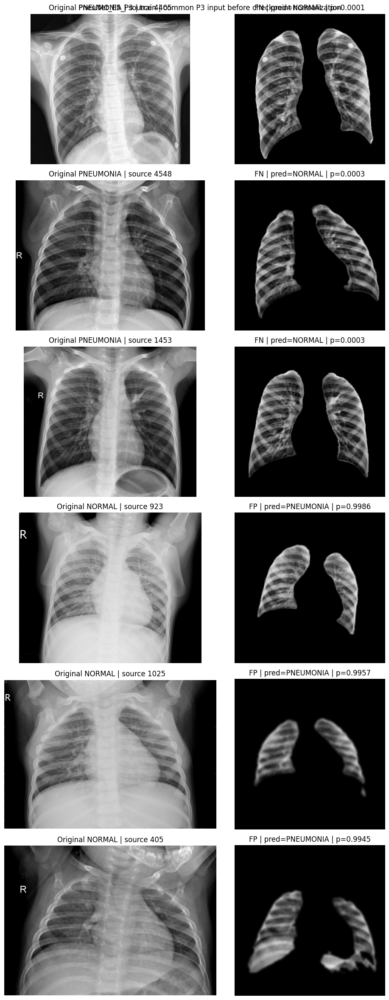

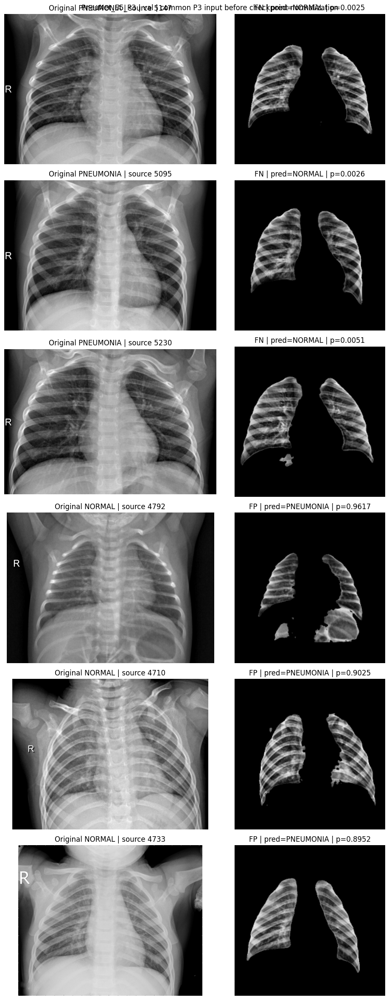

=== PneuNet_E5_P3 — TEST classification report (pelaporan, bukan seleksi) ===


,precision,recall,f1-score,support
class,,,,
NORMAL,0.949541,0.884615,0.915929,234.000000
PNEUMONIA,0.933498,0.971795,0.952261,390.000000
accuracy,0.939103,0.939103,0.939103,0.939103
macro avg,0.941519,0.928205,0.934095,624.000000
weighted avg,0.939514,0.939103,0.938637,624.000000


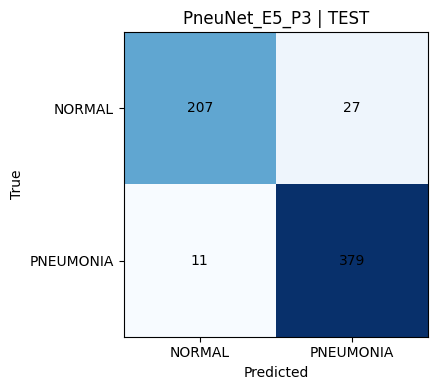

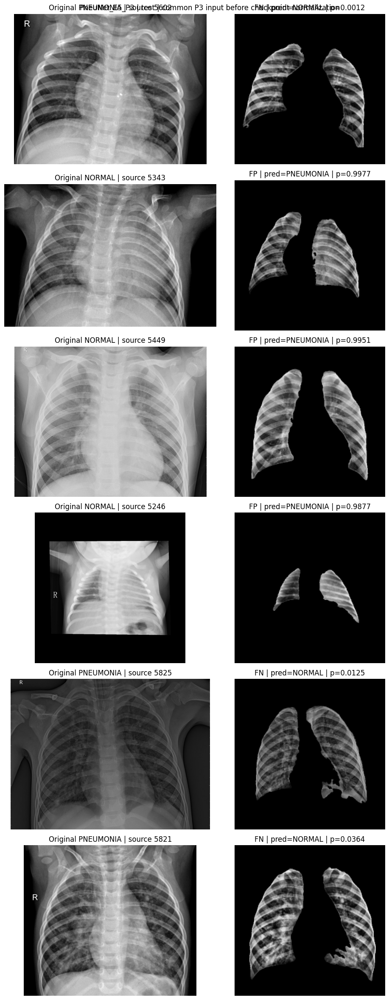

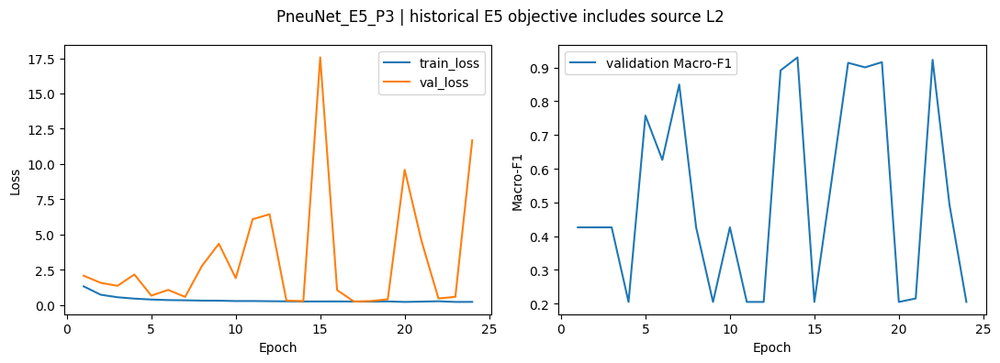

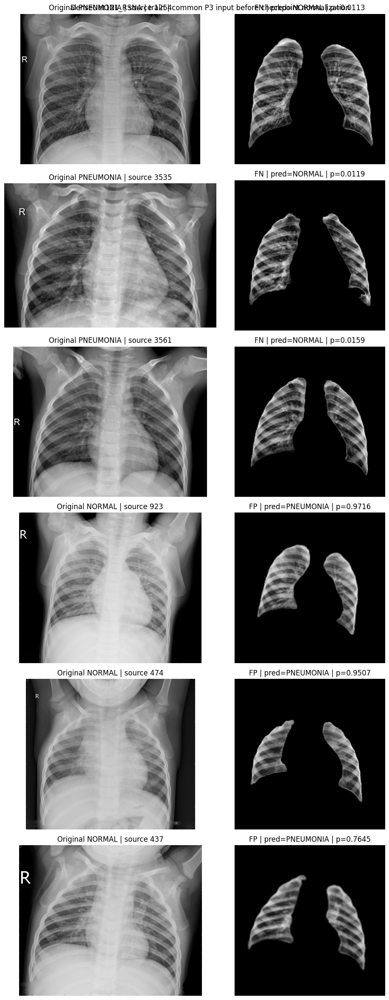

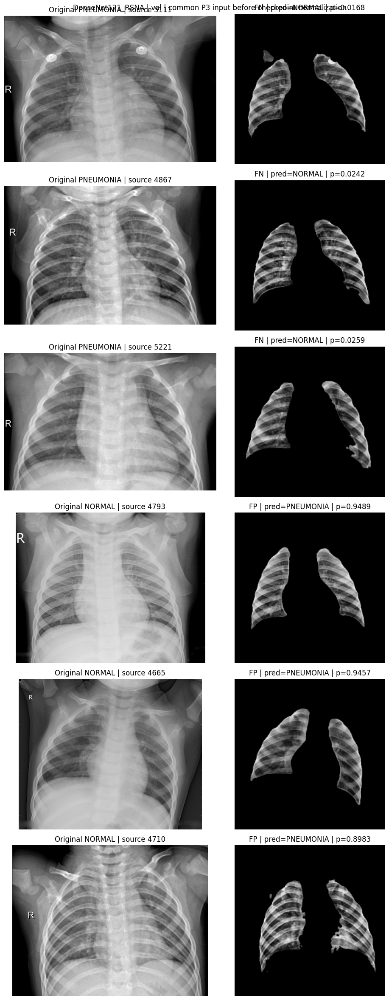

=== DenseNet121_RSNA — TEST classification report (pelaporan, bukan seleksi) ===


,precision,recall,f1-score,support
class,,,,
NORMAL,0.951542,0.923077,0.937093,234.000000
PNEUMONIA,0.954660,0.971795,0.963151,390.000000
accuracy,0.953526,0.953526,0.953526,0.953526
macro avg,0.953101,0.947436,0.950122,624.000000
weighted avg,0.953491,0.953526,0.953379,624.000000


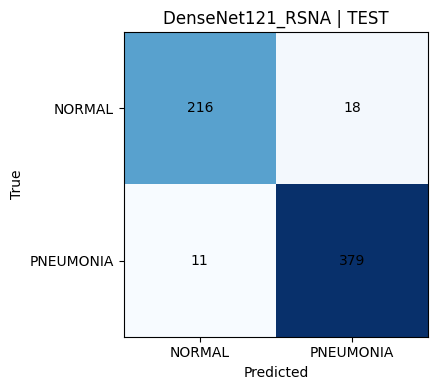

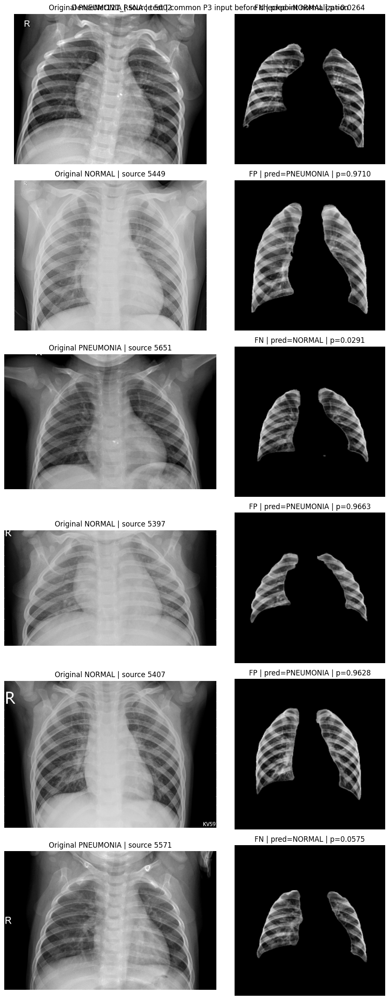

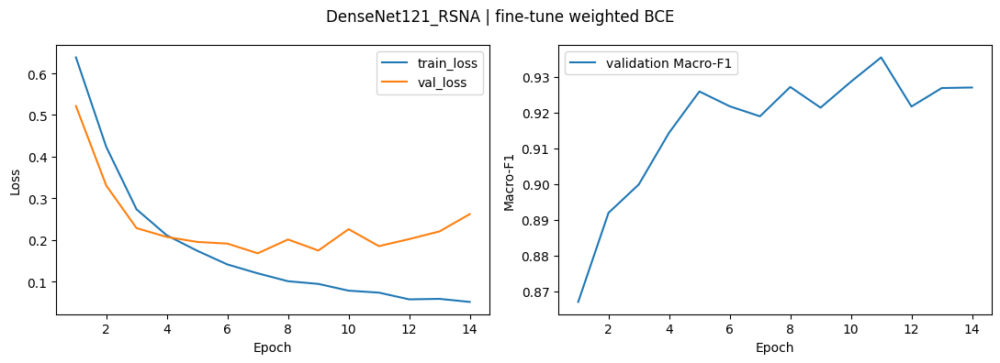

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

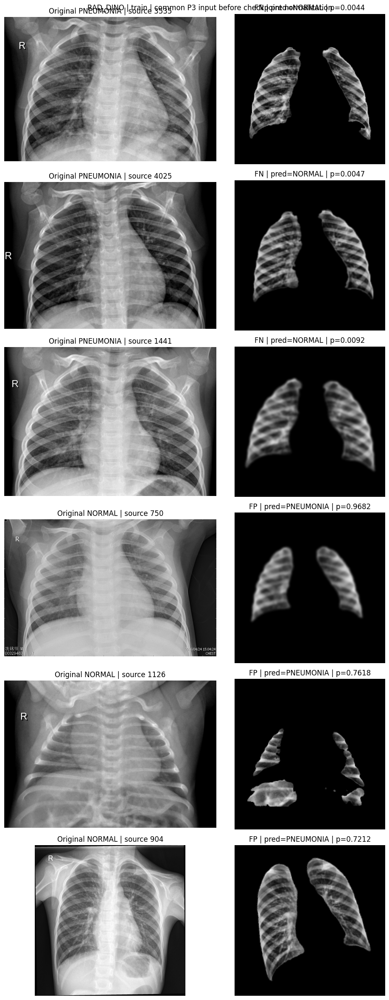

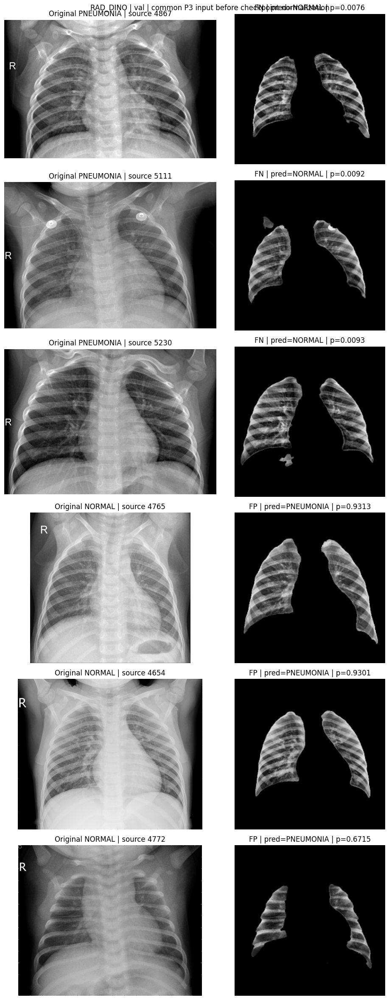

=== RAD_DINO — TEST classification report (pelaporan, bukan seleksi) ===


,precision,recall,f1-score,support
class,,,,
NORMAL,0.883065,0.935897,0.908714,234.000000
PNEUMONIA,0.960106,0.925641,0.942559,390.000000
accuracy,0.929487,0.929487,0.929487,0.929487
macro avg,0.921585,0.930769,0.925636,624.000000
weighted avg,0.931216,0.929487,0.929867,624.000000


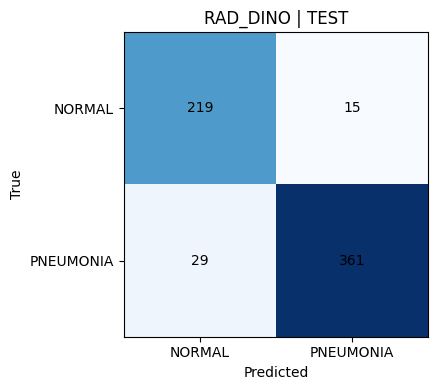

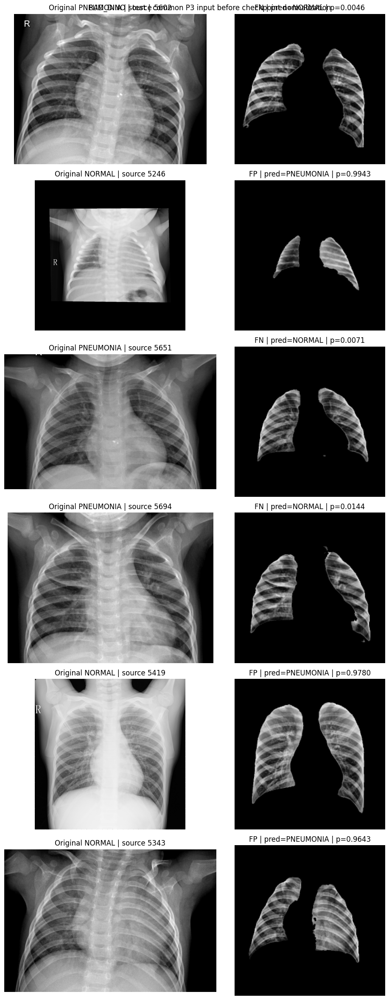

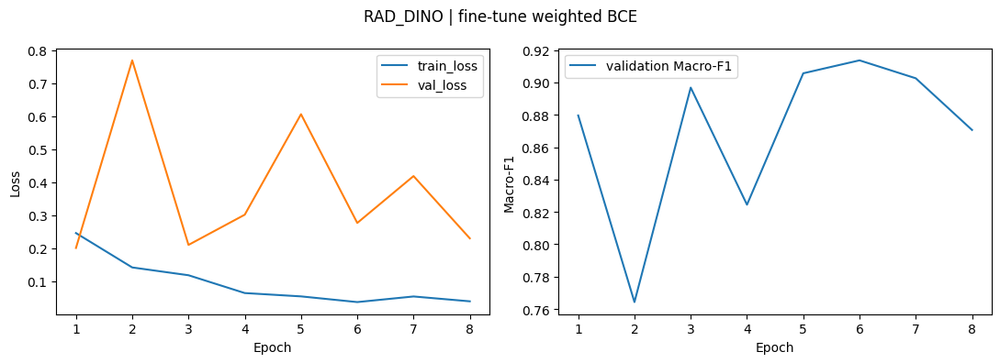

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

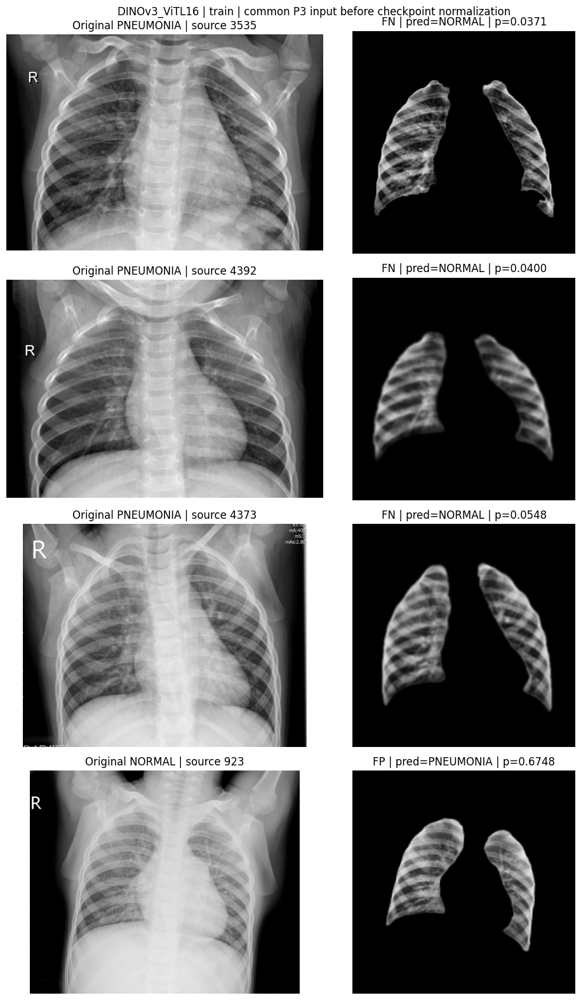

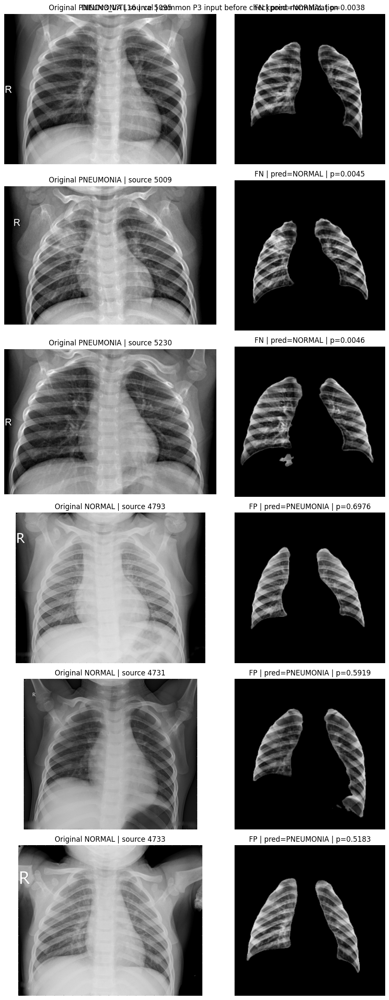

=== DINOv3_ViTL16 — TEST classification report (pelaporan, bukan seleksi) ===


,precision,recall,f1-score,support
class,,,,
NORMAL,0.917695,0.952991,0.935010,234.000000
PNEUMONIA,0.971129,0.948718,0.959792,390.000000
accuracy,0.950321,0.950321,0.950321,0.950321
macro avg,0.944412,0.950855,0.947401,624.000000
weighted avg,0.951091,0.950321,0.950499,624.000000


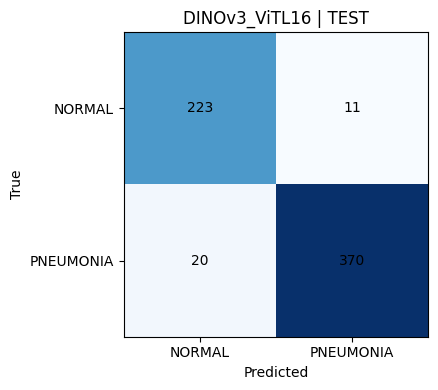

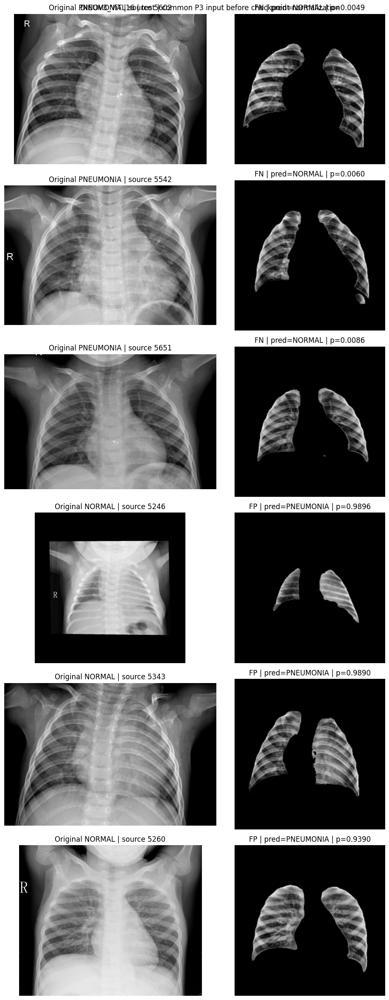

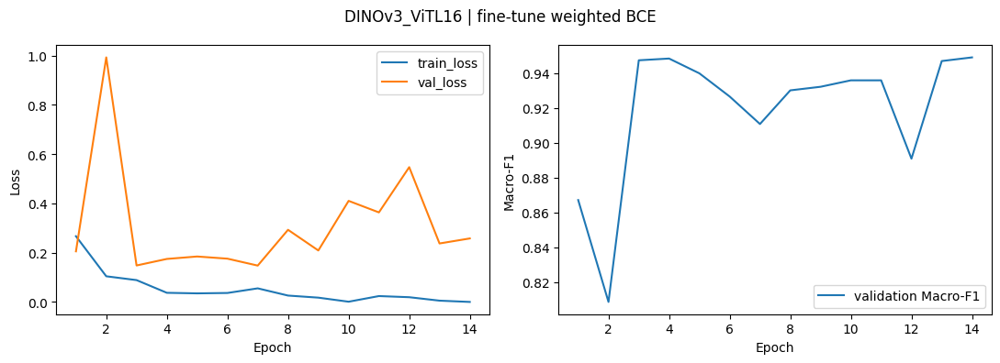

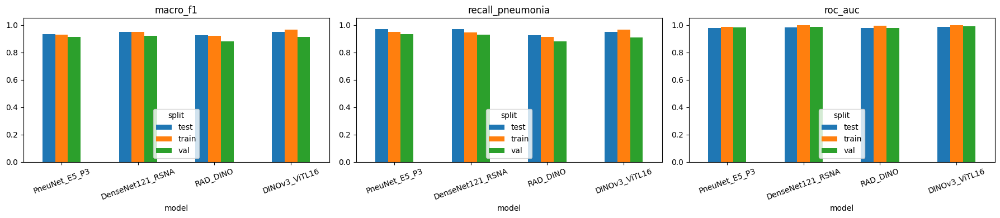

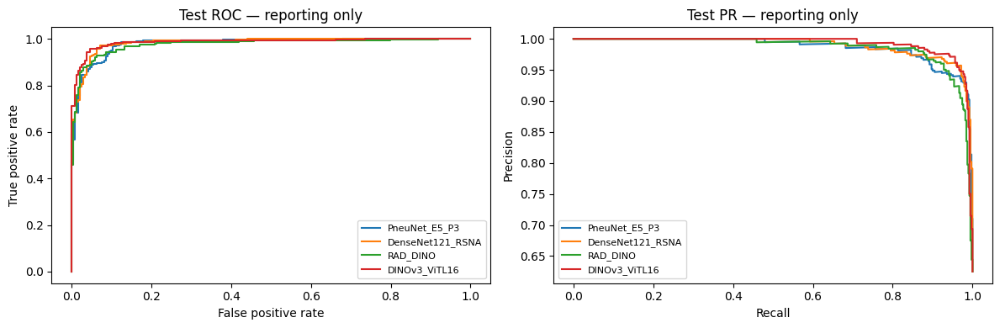

,model,split,accuracy,macro_f1,roc_auc,pr_auc,samples,threshold,precision_normal,recall_normal,f1_normal,precision_pneumonia,recall_pneumonia,f1_pneumonia,weighted_bce
0,PneuNet_E5_P3,train,0.944253,0.929044,0.984491,0.994681,4646,0.5,0.861989,0.933222,0.896192,0.976112,0.948086,0.961895,0.160279
1,PneuNet_E5_P3,val,0.931741,0.914026,0.983771,0.994592,586,0.5,0.828402,0.927152,0.875000,0.973621,0.933333,0.953052,0.168606
2,PneuNet_E5_P3,test,0.939103,0.934095,0.979728,0.987128,624,0.5,0.949541,0.884615,0.915929,0.933498,0.971795,0.952261,0.258656
3,DenseNet121_RSNA,train,0.959320,0.949208,0.996345,0.998762,4646,0.5,0.866909,0.994992,0.926545,0.998166,0.946926,0.971871,0.094334
4,DenseNet121_RSNA,val,0.935154,0.918952,0.985704,0.995005,586,0.5,0.826590,0.947020,0.882716,0.980630,0.931034,0.955189,0.167652
5,DenseNet121_RSNA,test,0.953526,0.950122,0.983706,0.989741,624,0.5,0.951542,0.923077,0.937093,0.954660,0.971795,0.963151,0.209207
6,RAD_DINO,train,0.934352,0.920086,0.993759,0.997950,4646,0.5,0.800673,0.992487,0.886321,0.997153,0.914153,0.953851,0.121687
7,RAD_DINO,val,0.899317,0.879628,0.978108,0.992722,586,0.5,0.732323,0.960265,0.830946,0.984536,0.878161,0.928311,0.200675
8,RAD_DINO,test,0.929487,0.925636,0.976079,0.986233,624,0.5,0.883065,0.935897,0.908714,0.960106,0.925641,0.942559,0.217298
9,DINOv3_ViTL16,train,0.973741,0.966753,0.999916,0.999970,4646,0.5,0.908194,0.999165,0.951510,0.999700,0.964907,0.981995,0.045142


,model,parameters_total,parameters_trainable,latency_ms_batch1,latency_ms_batch32,reference_retrained
0,PneuNet_E5_P3,785192,0,28.218435,120.384993,False
1,DenseNet121_RSNA,6948609,6948609,95.271824,92.614622,True
2,RAD_DINO,86581249,86581249,70.339638,163.424792,True
3,DINOv3_ViTL16,303130625,303130625,155.791381,412.154231,True


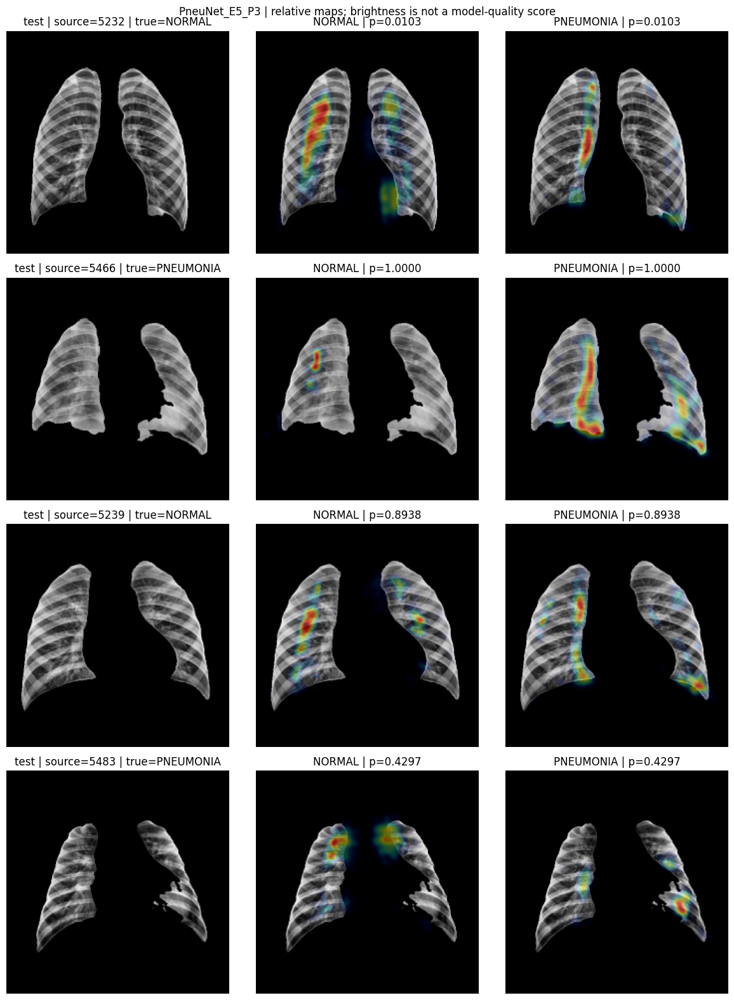

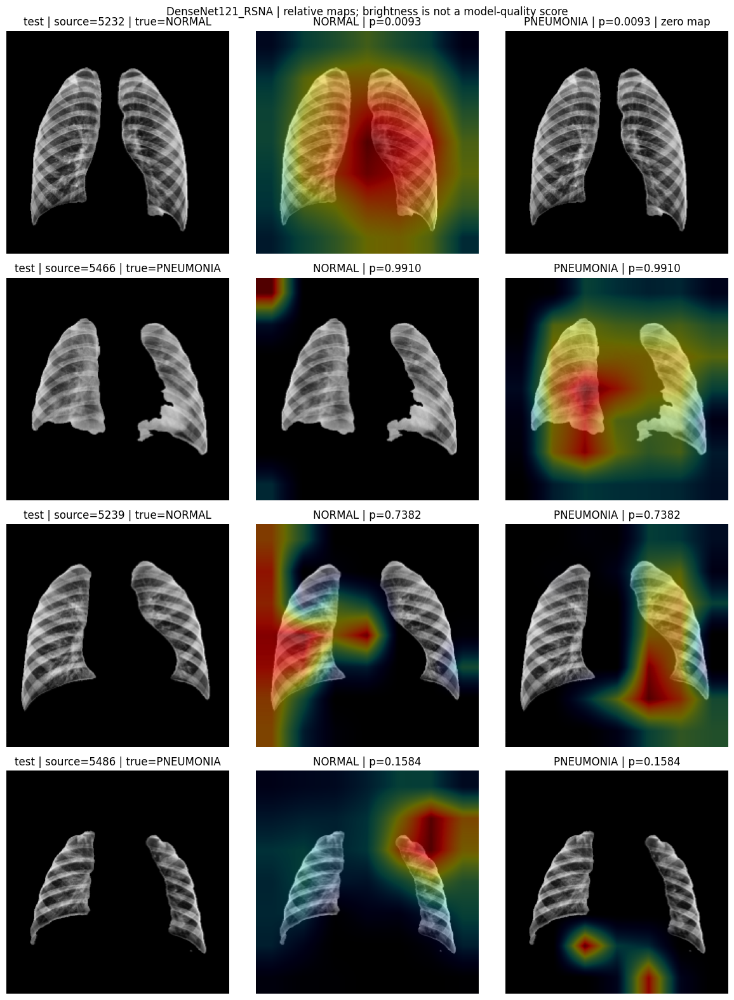

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

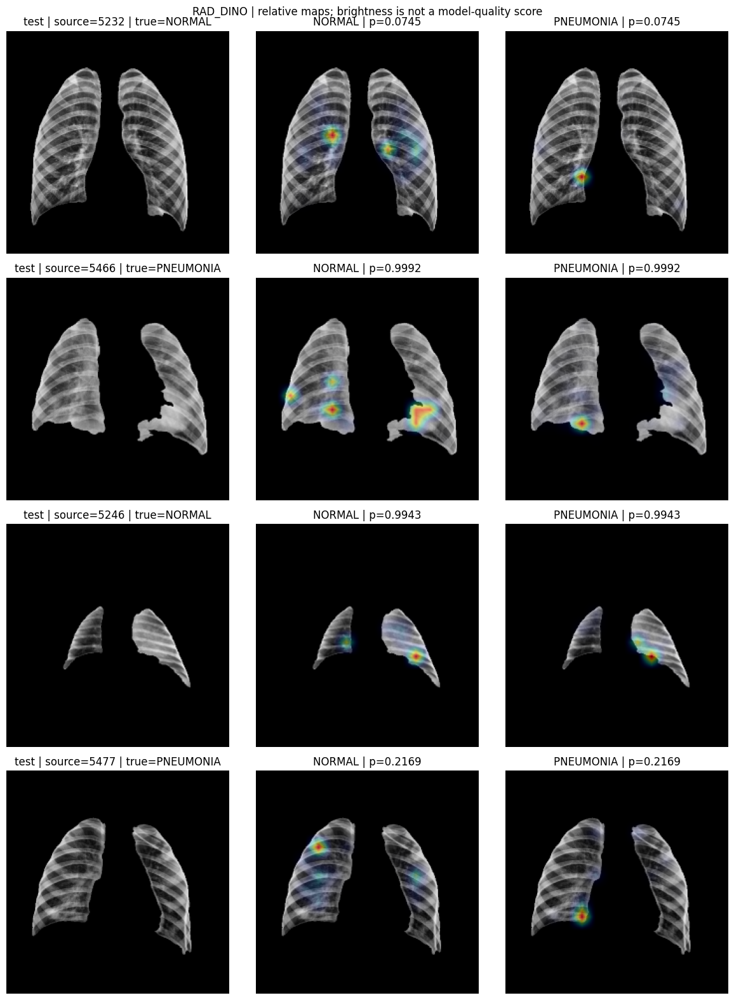

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

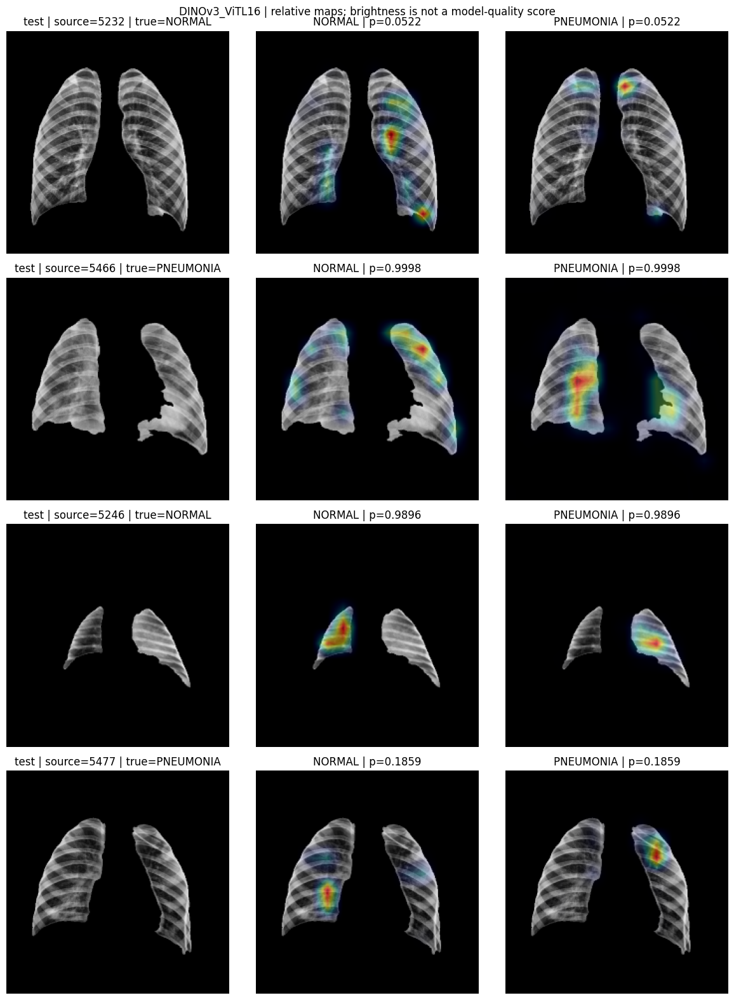

Full training requested: True | E5 is always checkpoint-only, never retrained.


In [8]:
# Full training always requires explicit opt-in.
smoke_results=[]
if RUN_SMOKE:
    smoke_results=run_all_smokes()
    display_smoke_summary()
benchmark_run_directory=Path(SAVED_BENCHMARK_RUN) if SAVED_BENCHMARK_RUN is not None else (
    Path(RESUME_RUN_DIRECTORY) if RESUME_RUN_DIRECTORY is not None else None)
if RUN_FULL_TRAINING:
    benchmark_run_directory=run_full_benchmark(RESUME_RUN_DIRECTORY)
if RUN_FULL_EVALUATION:
    if benchmark_run_directory is None:raise RuntimeError('Set SAVED_BENCHMARK_RUN/RESUME_RUN_DIRECTORY or finish training first.')
    benchmark_metrics=evaluate_benchmark(benchmark_run_directory)
if RUN_ATTRIBUTION:
    if benchmark_run_directory is None:raise RuntimeError('Set SAVED_BENCHMARK_RUN first.')
    attribution_cases=attribution_gallery(benchmark_run_directory,split='test')
print('Full training requested:',RUN_FULL_TRAINING)


## Hasil smoke aktual notebook

Cell berikut membaca `smoke_results` sesi ini atau file `smoke/<run>/<model>/smoke.json` yang benar-benar ditulis notebook dan cocok dengan protokol. Tidak memerlukan `OUTPUT_ROOT/validation.json`. Jika belum ada hasil smoke, pesan informatif ditampilkan tanpa error. Data smoke parsial/FAILED/OOM tetap dapat ditampilkan; hanya empat PASS lengkap yang lolos gate full training. Tabel ini merangkum pemeriksaan fungsional dan atribusi. Pengukuran VRAM ada di bagian berikut.


Output yang terlihat saat file dibuka adalah snapshot smoke audit terbaru. Rerun cell ini hanya membaca hasil aktual sesi/file smoke, tanpa mengeksekusi model.


In [ ]:
# Tidak membaca validation.json eksternal dan tidak menjalankan model/training.
if callable(globals().get('display_smoke_summary')):
    smoke_summary_table = display_smoke_summary()
else:
    print('Definisi smoke belum dimuat. Jalankan cell konfigurasi/definisi, lalu smoke; tidak perlu validation.json atau full training.')


Sumber: /home/arsyadmuhammad/AI Project/Pneumonia/output_benchmark_P3_seed42/smoke/20261119_042103_011322


,model,status,batch,precision,parameters,trainable,normalization_check,attribution_shape
0,PneuNet_E5_P3,PASS,32,float32,785192,0,PASS,"[1, 128, 112, 112]"
1,DenseNet121_RSNA,PASS,32,float32,6948609,6948609,PASS,"[1, 1024, 7, 7]"
2,RAD_DINO,PASS,32,float32,86581249,86581249,PASS,"[1, 257, 768]"
3,DINOv3_ViTL16,PASS,32,float32,303130625,303130625,PASS,"[1, 201, 1024]"


## 9. Benchmark VRAM FP32, batch fisik 32

- **Inference** mengukur satu forward dalam `eval()` dan `torch.no_grad()`.
- **Training-step** mengukur satu forward, backward, dan `optimizer.step()` dalam `train()`. Adam baru mengalokasikan state pada langkah ini. E5 memakai salinan `best.pt` seed 42, Adam asli, dan weighted BCE + kernel L2 sumber. Pretrained memakai checkpoint terbaik dari run terpilih dan optimizer benchmark. Tanpa run terpilih, pengukuran memakai bobot pretrained awal.
- **Full training** membaca peak historis dari `training.json` run terpilih. Angka mencakup sesi pelatihan yang tercatat, termasuk validasi antar epoch. N/A berarti pengukuran belum ada atau hanya mencakup sesi resume dengan riwayat peak sebelumnya tidak terekam.

Kedua pengukuran baru memakai batch P3 yang sama. Peak direset setelah model dan batch berada di GPU dan sebelum masing-masing fase dimulai. Angka allocated dan reserved mencakup memori yang sudah terpakai saat pengukuran dimulai. CUDA disinkronkan sebelum reset dan saat membaca peak. Update hanya terjadi pada salinan model dalam memori. Hasil tersimpan di `output_benchmark_P3_seed42/vram/`.

In [ ]:
VRAM_PROTOCOL_VERSION = 1

def source_e5_step_functions():
    """Reuse the original E5 optimizer builder and kernel L2 objective."""
    names = {'build_optimizer', 'kernel_l2'}
    namespace = {'torch': torch, 'nn': nn}
    for cell in _source['cells']:
        if cell['cell_type'] != 'code':
            continue
        for node in ast.parse(''.join(cell['source'])).body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                exec(compile(ast.Module(body=[node], type_ignores=[]),
                             str(SOURCE_NOTEBOOK), 'exec'), namespace)
    return namespace['build_optimizer'], namespace['kernel_l2']

def reset_vram_peak():
    torch.cuda.synchronize(DEVICE)
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(DEVICE)

def measure_vram_model(record, run_directory, host_batch, e5_optimizer, e5_l2):
    """Measure both phases on a disposable model; inference runs before the update."""
    name = record['model']
    is_e5 = name == 'PneuNet_E5_P3'
    model = make_model(name)
    if is_e5:
        checkpoint = E5_DIRECTORY/'best.pt'
    elif run_directory is not None:
        directory = run_directory/name
        check_saved_checkpoint(model, directory)
        checkpoint = directory/'best.pt'
    else:
        checkpoint = None
    if checkpoint is not None:
        record['checkpoint'] = str(checkpoint)
        record['checkpoint_sha256'] = sha256_file(checkpoint)
    else:
        record['initial_weights'] = model.metadata

    raw, labels = (tensor.to(DEVICE) for tensor in host_batch)
    assert raw.shape == (PHYSICAL_BATCH_SIZE, 1, IMG_SIZE, IMG_SIZE)
    assert raw.dtype == torch.float32 and not raw.requires_grad
    assert not torch.backends.cuda.matmul.allow_tf32 and not torch.backends.cudnn.allow_tf32
    model.eval()
    with torch.no_grad(), torch.autocast(device_type='cuda', enabled=False):
        reset_vram_peak()
        logits = model(raw)
        record['inference'] = gpu_peak()
    assert logits.shape == (PHYSICAL_BATCH_SIZE, 1) and logits.dtype == torch.float32
    assert torch.isfinite(logits).all()
    del logits

    model.train()
    if is_e5:
        model.requires_grad_(True)
        optimizer = e5_optimizer(model.backbone, TRAIN_CONFIG)
    else:
        optimizer = make_finetune_optimizer(model)
    group = optimizer.param_groups[0]
    record['optimizer'] = {'type': type(optimizer).__name__, **{
        key: group[key] for key in ('lr', 'betas', 'eps', 'weight_decay', 'foreach')}}
    record['trainable_parameters_in_step'] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    benchmark_seed()
    with torch.enable_grad(), torch.autocast(device_type='cuda', enabled=False):
        optimizer.zero_grad(set_to_none=True)
        reset_vram_peak()
        logits = model(raw)
        assert logits.shape == (PHYSICAL_BATCH_SIZE, 1) and logits.dtype == torch.float32
        loss = weighted_bce(logits, labels)
        if is_e5:
            loss = loss + e5_l2(model.backbone, TRAIN_CONFIG)
        if not torch.isfinite(loss):
            raise RuntimeError(f'Nonfinite training step loss: {name}')
        loss.backward()
        optimizer.step()
        record['training_step'] = gpu_peak()
    assert optimizer.state and all(float(state['step']) == 1. for state in optimizer.state.values())
    record.update(status='PASS', optimizer_updates=1, loss=float(loss.detach()))

def vram_run_key(run_directory):
    return str(Path(run_directory).resolve()) if run_directory is not None else None

def vram_table(run_directory, records):
    by_model = {record['model']: record for record in records}
    rows = []
    for name in MODEL_NAMES:
        record = by_model.get(name, {})
        full = {}
        if run_directory is not None and name != 'PneuNet_E5_P3':
            path = Path(run_directory)/name/'training.json'
            if path.is_file():
                info = json.loads(path.read_text())
                if (info.get('status') == 'TRAINED' and info.get('model') == name
                        and info.get('protocol_sha256') == benchmark_protocol_signature()
                        and info.get('resumed_after_epoch') == 0):
                    full = info
        phases = {'inference': record.get('inference', {}),
                  'training_step': record.get('training_step', {}),
                  'full_training': full}
        row = {'model': name}
        for phase, peaks in phases.items():
            for kind in ('allocated', 'reserved'):
                row[f'{phase}_{kind}_gib'] = peaks.get(f'peak_{kind}_gib')
        rows.append(row)
    return pd.DataFrame(rows)

def run_vram_benchmark(run_directory=None):
    """Run one batch per phase and model. Persist the measurements separately."""
    run_key = vram_run_key(run_directory)
    directory = OUTPUT_ROOT/'vram'/datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
    directory.mkdir(parents=True, exist_ok=False)
    payload = {'version': VRAM_PROTOCOL_VERSION, 'completed_run': run_key,
               'protocol_sha256': benchmark_protocol_signature(), 'batch': PHYSICAL_BATCH_SIZE,
               'precision': 'float32', 'amp': False, 'tf32': False, 'gpu': torch.cuda.get_device_name(DEVICE),
               'records': []}
    if run_key is not None:
        if not Path(run_key).is_dir():
            raise FileNotFoundError(run_key)
        prepare_benchmark_run(run_key)
    host_batch = next(iter(smoke_loader()))
    e5_optimizer, e5_l2 = source_e5_step_functions()
    for name in MODEL_NAMES:
        record = {'model': name}
        payload['records'].append(record)
        try:
            measure_vram_model(record, Path(run_key) if run_key else None, host_batch, e5_optimizer, e5_l2)
            print(name, 'VRAM PASS', flush=True)
        except torch.cuda.OutOfMemoryError as error:
            record.update(status='OOM', error=str(error))
            raise BenchmarkOOM(f'{name}: VRAM measurement OOM at FP32 batch {PHYSICAL_BATCH_SIZE}') from error
        except Exception as error:
            record.update(status='FAILED', error=f'{type(error).__name__}: {error}')
            raise
        finally:
            gc.collect()
            torch.cuda.empty_cache()
            write_json(directory/'measurements.json', payload)
            vram_table(run_key, payload['records']).to_csv(directory/'comparison.csv', index=False, na_rep='N/A')
    assert sha256_file(E5_DIRECTORY/'best.pt') == E5_CHECKPOINT_SHA256
    return directory

def display_vram_summary(run_directory=None):
    run_key = vram_run_key(run_directory)
    records = []
    for path in sorted((OUTPUT_ROOT/'vram').glob('*/measurements.json'), reverse=True):
        data = json.loads(path.read_text())
        if (data.get('version') == VRAM_PROTOCOL_VERSION and data.get('completed_run') == run_key
                and data.get('protocol_sha256') == benchmark_protocol_signature()):
            records = data['records']
            print('Hasil inference dan training-step:', path)
            break
    if run_key is not None:
        print('Sumber full-training peak:', Path(run_key)/'<model>'/'training.json')
    table = vram_table(run_key, records)
    shown = table.set_index('model')
    shown.columns = pd.MultiIndex.from_product([
        ('Inference', 'Training-step', 'Full training'), ('Allocated GiB', 'Reserved GiB')])
    display(shown.astype(object).map(lambda value: 'N/A' if pd.isna(value) else f'{value:.3f}'))
    return table


In [ ]:
vram_run_directory = globals().get('benchmark_run_directory', SAVED_BENCHMARK_RUN)
if RUN_VRAM_BENCHMARK:
    vram_measurement_directory = run_vram_benchmark(vram_run_directory)
vram_summary = display_vram_summary(vram_run_directory)

PneuNet_E5_P3 VRAM PASS


DenseNet121_RSNA VRAM PASS


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

RAD_DINO VRAM PASS


Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

DINOv3_ViTL16 VRAM PASS


Hasil inference dan training-step: /home/arsyadmuhammad/AI Project/Pneumonia/output_benchmark_P3_seed42/vram/20261119_080239_519610/measurements.json
Sumber full-training peak: /home/arsyadmuhammad/AI Project/Pneumonia/output_benchmark_P3_seed42/runs/20261119_044615_013633/<model>/training.json


Inference              Training-step               \
                 Allocated GiB Reserved GiB Allocated GiB Reserved GiB   
model                                                                    
PneuNet_E5_P3            2.536        3.139        11.769       13.844   
DenseNet121_RSNA         0.341        0.412         4.015        4.725   
RAD_DINO                 0.691        0.852         5.671        6.158   
DINOv3_ViTL16            1.514        1.684         4.619        4.705   

                 Full training               
                 Allocated GiB Reserved GiB  
model                                        
PneuNet_E5_P3              N/A          N/A  
DenseNet121_RSNA         4.066        4.754  
RAD_DINO                 6.319        6.846  
DINOv3_ViTL16            5.140        5.363

## 10. Efisiensi model pada GPU A100

Bagian ini memuat checkpoint terbaik dari `SAVED_BENCHMARK_RUN` dan checkpoint eksperimen asli untuk E5. Aktifkan `RUN_GPU_EFFICIENCY` di cell eksekusi bagian ini untuk mengukur ulang setelah cell definisi dimuat. Bagian ini dapat dijalankan tanpa cell eksekusi training, evaluasi, atribusi, atau VRAM.

Latency memakai 32 sampel test P3 pertama dalam urutan split. Batch 1 memakai sampel pertama yang sama. Input sudah di GPU saat forward, termasuk normalisasi checkpoint tetapi di luar I/O, preprocessing, transfer, dan loading model. Setiap model dan ukuran batch diukur dalam 3 sesi. Masing-masing sesi melakukan 30 warmup dan 100 pengukuran CUDA Events dalam mode eval, no_grad, FP32 dengan AMP dan TF32 mati. Throughput dihitung sebagai ukuran batch dibagi rerata latensi.

`nvidia-smi pmon` memeriksa aktivitas SM dan memori proses lain sebelum, selama, dan setelah pengukuran. Jika aktivitas terdeteksi, sesi GPU terkait dibuang. Log menyimpan VRAM tersedia dan sampel aktivitas. Sampling berselang dapat melewatkan aktivitas singkat.

Parameter dihitung dari model checkpoint. MAC/FLOP dihitung pada input 1×1×224×224 dengan `FlopCounterMode`, menggunakan 1 MAC = 2 FLOPs. Angka mencakup operasi yang terdaftar. Attention dihitung melalui perkalian matriks pada backend SDPA math saat menghitung operasi. Biaya softmax, aktivasi, normalisasi, padding, perpindahan data, dan operasi elementwise pada pooling kustom tidak seluruhnya terhitung. Backend saat benchmark GPU mengikuti konfigurasi model.

Profiler CPU/CUDA berjalan terpisah untuk E5 dan DenseNet pada batch 1 dan 32. Penjumlahan durasi kernel adalah waktu aktivitas CUDA, yang dapat tumpang tindih. Durasi API launch berasal dari sisi host. Kategori operator memakai event induk dan scope depthwise, sedangkan jumlah kernel diambil dari aktivitas CUDA pada trace. Angka profiler tidak dipakai sebagai latency CUDA Events.

Tabel, grafik, ringkasan, dan trace disimpan ke `SAVED_BENCHMARK_RUN/efficiency_analysis/<timestamp>/`.

Rujukan [PyTorch Profiler](https://docs.pytorch.org/docs/2.8/profiler.html), [CUDA Event](https://docs.pytorch.org/docs/2.8/generated/torch.cuda.Event.html), [FlopCounterMode](https://github.com/pytorch/pytorch/blob/v2.8.0/torch/utils/flop_counter.py).

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from contextlib import contextmanager
from threading import Event
import subprocess
from torch.nn.attention import SDPBackend, sdpa_kernel
from torch.profiler import ProfilerActivity, profile, record_function
from torch.utils.flop_counter import FlopCounterMode

EFFICIENCY_BATCHES = (1, 32)
EFFICIENCY_WARMUP = 30
EFFICIENCY_REPEATS = 100
EFFICIENCY_SESSIONS = 3
PROFILE_REPEATS = 5
PROFILE_MODELS = ('PneuNet_E5_P3', 'DenseNet121_RSNA')


def load_efficiency_checkpoint(name, run_directory):
    model = BenchmarkBinary(name).eval()
    check_saved_checkpoint(model, run_directory/name)
    checkpoint = E5_DIRECTORY/'best.pt' if name == 'PneuNet_E5_P3' else run_directory/name/'best.pt'
    return model, checkpoint


def efficiency_complexity(model, raw):
    # Count dense attention products explicitly via the mathematical SDPA backend.
    # This pass computes arithmetic estimates only. GPU timings keep the usual backend.
    with torch.no_grad(), sdpa_kernel(SDPBackend.MATH), FlopCounterMode(display=False) as counter:
        logits = model(raw)
    assert logits.shape == (1, 1) and logits.dtype == torch.float32 and torch.isfinite(logits).all()
    by_operator = {str(op): int(count) for op, count in counter.get_flop_counts()['Global'].items()}
    flops = sum(by_operator.values())
    if model.name in HF_REPOS and by_operator.get('aten.bmm', 0) == 0:
        raise RuntimeError(f'{model.name}: no attention matrix products counted')
    return {'model': model.name, 'parameters': sum(p.numel() for p in model.parameters()),
            'counted_macs': flops//2, 'counted_flops': flops}, by_operator


def gpu_activity_sample(uuid):
    result = subprocess.run(['nvidia-smi', 'pmon', '-i', uuid, '-c', '1', '-s', 'u'],
                            check=True, capture_output=True, text=True, timeout=10)
    external = []
    valid_rows = 0
    for line in result.stdout.splitlines():
        fields = line.split()
        if len(fields) < 5 or not fields[0].isdigit():
            continue
        valid_rows += 1
        if not fields[1].isdigit() or int(fields[1]) == os.getpid():
            continue
        utilization = [int(value) for value in fields[3:5] if value.isdigit()]
        if any(value > 0 for value in utilization):
            external.append({'pid': int(fields[1]), 'sm_pct': fields[3], 'mem_pct': fields[4]})
    if not valid_rows:
        raise RuntimeError('nvidia-smi pmon did not return per-process utilization')
    free, total = torch.cuda.mem_get_info(DEVICE)
    return {'utc': datetime.now(timezone.utc).isoformat(), 'external_activity': external,
            'free_gib': free/2**30, 'total_gib': total/2**30}


class EfficiencyGPUOccupied(RuntimeError):
    pass


def audit_gpu_sample(directory, scope, sample):
    with (directory/'gpu_samples.jsonl').open('a') as file:
        file.write(json.dumps({'scope': scope, **sample})+'\n')


def wait_for_quiet_gpu(uuid, directory, scope, wait_seconds):
    deadline = time.monotonic() + wait_seconds
    consecutive = 0
    while True:
        sample = gpu_activity_sample(uuid)
        audit_gpu_sample(directory, scope, sample)
        consecutive = consecutive + 1 if not sample['external_activity'] else 0
        if consecutive == 3:
            return
        if time.monotonic() >= deadline:
            raise EfficiencyGPUOccupied(f'GPU busy before {scope}')
        time.sleep(1)


@contextmanager
def check_gpu_during(uuid, directory, scope):
    stop = Event()

    def monitor():
        busy = False
        while True:
            sample = gpu_activity_sample(uuid)
            audit_gpu_sample(directory, scope, sample)
            busy |= bool(sample['external_activity'])
            if stop.wait(0.35):
                return busy

    with ThreadPoolExecutor(max_workers=1) as pool:
        job = pool.submit(monitor)
        try:
            yield
        finally:
            stop.set()
            busy = job.result()
        # Sample after the last events to cover the final NVML sampling interval.
        time.sleep(1)
        sample = gpu_activity_sample(uuid)
        audit_gpu_sample(directory, scope, sample)
        if busy or sample['external_activity']:
            raise EfficiencyGPUOccupied(f'External GPU activity sampled during {scope}')


@torch.no_grad()
def efficiency_latency(model, raw, uuid, directory):
    rows = []
    for session in range(1, EFFICIENCY_SESSIONS+1):
        order = EFFICIENCY_BATCHES if session % 2 else EFFICIENCY_BATCHES[::-1]
        for batch in order:
            inputs = raw[:batch]
            scope = f'{model.name}/b{batch}/session{session}'
            starts = [torch.cuda.Event(enable_timing=True) for _ in range(EFFICIENCY_REPEATS)]
            ends = [torch.cuda.Event(enable_timing=True) for _ in range(EFFICIENCY_REPEATS)]
            with check_gpu_during(uuid, directory, scope):
                for _ in range(EFFICIENCY_WARMUP):
                    model(inputs)
                # Initialize timing events outside the measured workload.
                for start, end in zip(starts, ends):
                    start.record()
                    end.record()
                torch.cuda.synchronize(DEVICE)
                for start, end in zip(starts, ends):
                    start.record()
                    model(inputs)
                    end.record()
                torch.cuda.synchronize(DEVICE)
            for trial, (start, end) in enumerate(zip(starts, ends), 1):
                rows.append({'model': model.name, 'batch': batch, 'session': session,
                             'trial': trial, 'ms_batch': start.elapsed_time(end)})
    return rows


def latency_statistics(frame, keys):
    rows = []
    for group, samples in frame.groupby(keys, sort=False):
        values = samples.ms_batch.to_numpy()
        row = dict(zip(keys, group))
        batch = row['batch']
        rows.append({**row, 'samples': len(values), 'mean_ms_batch': values.mean(),
                     'median_ms_batch': np.median(values), 'std_ms_batch': values.std(ddof=1),
                     'p95_ms_batch': np.percentile(values, 95),
                     'mean_ms_image': values.mean()/batch, 'median_ms_image': np.median(values)/batch,
                     'throughput_images_s': 1000*batch/values.mean()})
    return pd.DataFrame(rows)


@contextmanager
def mark_depthwise_convolutions(model):
    handles = []
    scopes = {}

    def enter(module, _inputs):
        scope = record_function('efficiency::depthwise_conv2d')
        scope.__enter__()
        scopes[module] = scope

    def exit_scope(module, _inputs, _output):
        scopes.pop(module).__exit__(None, None, None)

    try:
        for module in model.modules():
            if isinstance(module, nn.Conv2d) and module.groups == module.in_channels and module.groups > 1:
                handles.append(module.register_forward_pre_hook(enter))
                handles.append(module.register_forward_hook(exit_scope, always_call=True))
        yield
    finally:
        for handle in handles:
            handle.remove()


def profiler_category(event):
    parents = set()
    while event is not None:
        parents.add(event.name)
        event = event.cpu_parent
    if 'aten::pad' in parents or 'aten::constant_pad_nd' in parents:
        return 'F.pad'
    memory_ops = {'aten::copy_', 'aten::_to_copy', 'aten::cat', 'aten::clone', 'aten::contiguous',
                  'aten::repeat', 'aten::fill_', 'aten::zero_'}
    if parents & memory_ops:
        return 'Memory movement / initialization'
    conv_ops = {'aten::conv2d', 'aten::convolution', 'aten::_convolution'}
    if parents & conv_ops:
        return 'Depthwise convolution' if 'efficiency::depthwise_conv2d' in parents else 'Other convolution'
    return 'Other operators'


def profile_gpu_forward(model, raw, uuid, directory):
    batch = len(raw)
    scope = f'{model.name}/profiler/b{batch}'
    with torch.no_grad(), check_gpu_during(uuid, directory, scope):
        for _ in range(5):
            model(raw)
        torch.cuda.synchronize(DEVICE)
        with mark_depthwise_convolutions(model), profile(
                activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
                record_shapes=True, profile_memory=True) as profiler:
            for _ in range(PROFILE_REPEATS):
                with record_function('efficiency::forward'):
                    model(raw)
            torch.cuda.synchronize(DEVICE)

    trace_path = directory/f'trace_{model.name}_b{batch}.json'
    profiler.export_chrome_trace(str(trace_path))
    trace = json.loads(trace_path.read_text())['traceEvents']
    gpu_events = [event for event in trace if event.get('ph') == 'X' and
                  event.get('cat') in ('kernel', 'gpu_memcpy', 'gpu_memset')]
    kernels = [event for event in gpu_events if event['cat'] == 'kernel']
    memory_events = [event for event in gpu_events if event['cat'] != 'kernel']
    launches = [event for event in trace if event.get('ph') == 'X' and
                event.get('cat') in ('cuda_runtime', 'cuda_driver') and
                'launchkernel' in event.get('name', '').lower()]
    if not kernels:
        raise RuntimeError(f'No CUDA kernels captured for {scope}')

    operators = []
    for event in profiler.events():
        if event.device_type != torch.autograd.DeviceType.CPU or not event.kernels:
            continue
        operators.append({'operator': event.name, 'category': profiler_category(event),
                          'linked_activities': len(event.kernels),
                          'cuda_us': sum(kernel.duration for kernel in event.kernels)})
    if not operators:
        raise RuntimeError(f'No linked CUDA activities captured for {scope}')
    keys = {'model': model.name, 'batch': batch}
    operator_table = pd.DataFrame(operators).groupby(['category', 'operator'], as_index=False).sum()
    category_table = operator_table.groupby('category', as_index=False).sum(numeric_only=True)
    for table in (operator_table, category_table):
        table['cuda_ms_batch'] = table.pop('cuda_us')/PROFILE_REPEATS/1000
        table['linked_activities_batch'] = table.pop('linked_activities')/PROFILE_REPEATS
        table['model'], table['batch'] = model.name, batch
    return ({**keys, 'kernels_per_batch': len(kernels)/PROFILE_REPEATS,
             'kernel_ms_batch': sum(event['dur'] for event in kernels)/PROFILE_REPEATS/1000,
             'gpu_memcpy_memset_per_batch': len(memory_events)/PROFILE_REPEATS,
             'gpu_memcpy_memset_ms_batch': sum(event['dur'] for event in memory_events)/PROFILE_REPEATS/1000,
             'host_launch_calls_per_batch': len(launches)/PROFILE_REPEATS,
             'host_launch_ms_batch': sum(event['dur'] for event in launches)/PROFILE_REPEATS/1000},
            operator_table, category_table)


def efficiency_charts(directory, comparison):
    labels = ['E5', 'DenseNet121', 'RAD-DINO', 'DINOv3-L']
    order = list(MODEL_NAMES)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for axis, column, label in zip(axes, ('parameters', 'counted_flops'), ('Parameters (M)', 'Counted GFLOPs, batch 1')):
        values = comparison.drop_duplicates('model').set_index('model').reindex(order)[column]
        axis.bar(labels, values/(1e6 if column == 'parameters' else 1e9))
        axis.set_ylabel(label)
    fig.tight_layout()
    fig.savefig(directory/'parameters_flops.png', dpi=150)
    plt.close(fig)
    if comparison['median_ms_batch'].notna().any():
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        for axis, column, label in zip(axes, ('median_ms_batch', 'throughput_images_s'),
                                       ('Median latency (ms/batch)', 'Throughput (images/s)')):
            values = comparison.pivot(index='model', columns='batch', values=column).reindex(order)
            values.index = labels
            values.plot.bar(ax=axis, rot=0)
            axis.set_ylabel(label)
        fig.tight_layout()
        fig.savefig(directory/'latency_throughput.png', dpi=150)
        plt.close(fig)


def write_efficiency_report(directory, complexity, samples, profiles, categories):
    design = pd.DataFrame([(name, batch) for name in MODEL_NAMES for batch in EFFICIENCY_BATCHES],
                          columns=['model', 'batch'])
    comparison = design.merge(complexity, on='model', how='left')
    if samples:
        frame = pd.DataFrame(samples)
        frame.to_csv(directory/'latency_trials.csv', index=False)
        latency_statistics(frame, ['model', 'batch', 'session']).to_csv(directory/'latency_sessions.csv', index=False)
        comparison = comparison.merge(latency_statistics(frame, ['model', 'batch']), on=['model', 'batch'], how='left')
    else:
        for column in ('samples', 'mean_ms_batch', 'median_ms_batch', 'std_ms_batch', 'p95_ms_batch',
                       'mean_ms_image', 'median_ms_image', 'throughput_images_s'):
            comparison[column] = np.nan
    comparison.to_csv(directory/'comparison.csv', index=False, na_rep='N/A')
    efficiency_charts(directory, comparison)
    if profiles:
        profile_table = pd.DataFrame(profiles)
        profile_table.to_csv(directory/'profile_summary.csv', index=False)
        category_table = pd.concat(categories, ignore_index=True)
        category_table.to_csv(directory/'profile_categories.csv', index=False)
    else:
        return
    summary = []
    for batch in EFFICIENCY_BATCHES:
        rows = profile_table[profile_table.batch == batch].set_index('model')
        if not set(PROFILE_MODELS).issubset(rows.index):
            continue
        e5, dense = PROFILE_MODELS
        categories_batch = category_table[category_table.batch == batch]
        times = categories_batch.pivot(index='category', columns='model', values='cuda_ms_batch').fillna(0.)
        delta = (times[e5] - times[dense]).sort_values(ascending=False)
        summary.append(f'Batch {batch}: kernel E5 {rows.loc[e5, "kernels_per_batch"]:.0f} vs DenseNet {rows.loc[dense, "kernels_per_batch"]:.0f} per batch. '
                       f'Waktu kernel: {rows.loc[e5, "kernel_ms_batch"]:.3f} vs {rows.loc[dense, "kernel_ms_batch"]:.3f} ms/batch. '
                       f'Selisih CUDA E5 minus DenseNet per kategori: '+', '.join(
                       f'{name} {value:+.3f} ms' for name, value in delta.items())+'.')
        summary.append(f'Waktu panggilan launch host: {rows.loc[e5, "host_launch_ms_batch"]:.3f} vs '
                       f'{rows.loc[dense, "host_launch_ms_batch"]:.3f} ms/batch. Ini durasi panggilan API pada CPU.')
    (directory/'bottlenecks.txt').write_text('\n'.join(summary)+'\n')


def run_efficiency_analysis(run_directory, gpu_wait_seconds=120):
    run_directory = Path(run_directory).resolve(strict=True)
    prepare_benchmark_run(run_directory)
    properties = torch.cuda.get_device_properties(DEVICE)
    if 'A100' not in properties.name:
        raise RuntimeError(f'Efficiency benchmark requires A100, found {properties.name}')
    uuid = str(properties.uuid)
    if not uuid.startswith('GPU-'):
        uuid = 'GPU-' + uuid
    directory = run_directory/'efficiency_analysis'/datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
    directory.mkdir(parents=True, exist_ok=False)
    raw_cpu, _ = next(iter(loader('test')))
    assert raw_cpu.shape == (32, 1, 224, 224) and raw_cpu.dtype == torch.float32
    assert not torch.backends.cuda.matmul.allow_tf32 and not torch.backends.cudnn.allow_tf32
    checkpoints = {}
    free, total = torch.cuda.mem_get_info(DEVICE)
    metadata = {'status': 'RUNNING', 'gpu': properties.name, 'gpu_uuid': uuid,
                'free_gib_at_start': free/2**30, 'total_gib': total/2**30,
                'torch': torch.__version__, 'cuda': torch.version.cuda, 'cudnn': torch.backends.cudnn.version(),
                'physical_batches': list(EFFICIENCY_BATCHES), 'precision': 'FP32', 'tf32': False, 'amp': False,
                'warmup': EFFICIENCY_WARMUP, 'repeats': EFFICIENCY_REPEATS, 'sessions': EFFICIENCY_SESSIONS,
                'activity_monitor': 'nvidia-smi pmon 1-second samples, external SM and memory activity',
                'test_source_indices': DATASETS['test'].source_indices[:32].tolist(),
                'input_sha256': hashlib.sha256(raw_cpu.numpy().tobytes()).hexdigest(), 'checkpoints': checkpoints}
    write_json(directory/'environment.json', metadata)
    complexity, operators = [], []
    print('Efficiency analysis', directory, flush=True)
    for name in MODEL_NAMES:
        model, path = load_efficiency_checkpoint(name, run_directory)
        checkpoints[name] = {'path': str(path), 'sha256': sha256_file(path)}
        counts, by_operator = efficiency_complexity(model, raw_cpu[:1])
        complexity.append(counts)
        operators.extend({'model': name, 'operator': op, 'counted_flops': n} for op, n in by_operator.items())
        print(name, 'complexity counted', flush=True)
        del model
        gc.collect()
    complexity = pd.DataFrame(complexity)
    complexity.to_csv(directory/'complexity.csv', index=False)
    pd.DataFrame(operators).to_csv(directory/'flops_by_operator.csv', index=False)
    samples, profiles, profile_operators, categories = [], [], [], []
    write_efficiency_report(directory, complexity, samples, profiles, categories)
    try:
        wait_for_quiet_gpu(uuid, directory, 'initial', gpu_wait_seconds)
        raw_gpu = raw_cpu.to(DEVICE)
        for name in MODEL_NAMES:
            model, _ = load_efficiency_checkpoint(name, run_directory)
            model.to(DEVICE)
            try:
                wait_for_quiet_gpu(uuid, directory, name, gpu_wait_seconds)
                with torch.autocast(device_type='cuda', enabled=False):
                    samples.extend(efficiency_latency(model, raw_gpu, uuid, directory))
                    if name in PROFILE_MODELS:
                        for batch in EFFICIENCY_BATCHES:
                            wait_for_quiet_gpu(uuid, directory, f'{name}/profile/b{batch}', gpu_wait_seconds)
                            row, category_ops, totals = profile_gpu_forward(model, raw_gpu[:batch], uuid, directory)
                            profiles.append(row)
                            profile_operators.append(category_ops)
                            categories.append(totals)
                print(name, 'GPU efficiency measured', flush=True)
            finally:
                del model
                gc.collect()
                torch.cuda.empty_cache()
        metadata['status'] = 'COMPLETE'
    except EfficiencyGPUOccupied as error:
        metadata.update(status='GPU_BUSY', detail=str(error))
        print(error, flush=True)
    except Exception as error:
        metadata.update(status='FAILED', detail=f'{type(error).__name__}: {error}')
        raise
    finally:
        write_efficiency_report(directory, complexity, samples, profiles, categories)
        if profile_operators:
            pd.concat(profile_operators, ignore_index=True).to_csv(directory/'profile_operators.csv', index=False)
        write_json(directory/'environment.json', metadata)
    return directory


def display_efficiency_analysis(run_directory):
    from IPython.display import Image as NotebookImage
    if run_directory is None:
        print('Isi SAVED_BENCHMARK_RUN untuk menampilkan analisis efisiensi.')
        return
    folders = sorted((Path(run_directory)/'efficiency_analysis').glob('*/comparison.csv'), reverse=True)
    if not folders:
        print('Belum ada pengukuran efisiensi tersimpan. Aktifkan RUN_GPU_EFFICIENCY dan jalankan cell ini.')
        return
    comparison = folders[0]
    directory = comparison.parent
    environment = json.loads((directory/'environment.json').read_text())
    print('Analisis efisiensi', directory, '|', environment['status'])
    if environment.get('detail'):
        print(environment['detail'])
    table = pd.read_csv(comparison)
    display(table.round(3).astype(object).where(table.notna(), 'N/A'))
    for filename in ('parameters_flops.png', 'latency_throughput.png'):
        image_path = directory/filename
        if image_path.is_file():
            display(NotebookImage(filename=str(image_path)))
    for filename in ('profile_summary.csv', 'profile_categories.csv'):
        table_path = directory/filename
        if table_path.is_file():
            display(pd.read_csv(table_path).round(3))
    bottlenecks = directory/'bottlenecks.txt'
    if bottlenecks.is_file():
        print(bottlenecks.read_text())


Efficiency analysis /home/arsyadmuhammad/AI Project/Pneumonia/output_benchmark_P3_seed42/runs/20261119_044615_013633/efficiency_analysis/20261119_081015_112481


PneuNet_E5_P3 complexity counted


DenseNet121_RSNA complexity counted


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

RAD_DINO complexity counted


Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

DINOv3_ViTL16 complexity counted


GPU busy before initial


Analisis efisiensi /home/arsyadmuhammad/AI Project/Pneumonia/output_benchmark_P3_seed42/runs/20261119_044615_013633/efficiency_analysis/20261119_081015_112481 | GPU_BUSY
GPU busy before initial


,model,batch,parameters,counted_macs,counted_flops,samples,mean_ms_batch,median_ms_batch,std_ms_batch,p95_ms_batch,mean_ms_image,median_ms_image,throughput_images_s
0,PneuNet_E5_P3,1,785192,11406410240,22812820480,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
1,PneuNet_E5_P3,32,785192,11406410240,22812820480,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
2,DenseNet121_RSNA,1,6948609,2754462720,5508925440,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
3,DenseNet121_RSNA,32,6948609,2754462720,5508925440,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
4,RAD_DINO,1,86581249,23161228032,46322456064,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
5,RAD_DINO,32,86581249,23161228032,46322456064,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
6,DINOv3_ViTL16,1,303130625,62839899136,125679798272,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
7,DINOv3_ViTL16,32,303130625,62839899136,125679798272,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A


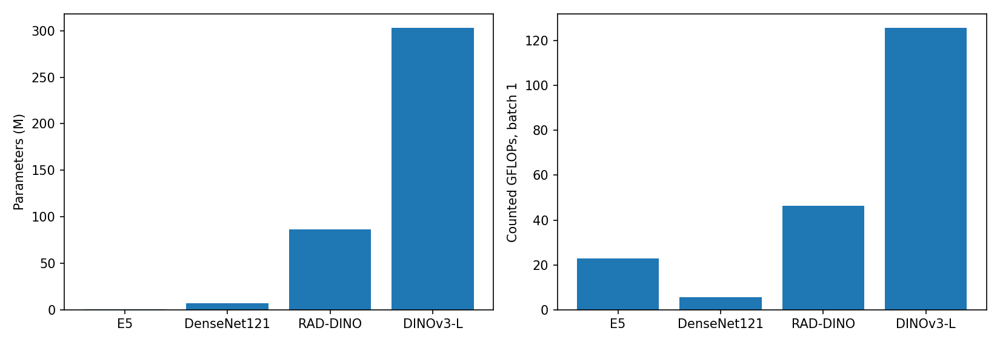

EFFICIENCY_STATUS GPU_BUSY /home/arsyadmuhammad/AI Project/Pneumonia/output_benchmark_P3_seed42/runs/20261119_044615_013633/efficiency_analysis/20261119_081015_112481


In [ ]:
RUN_GPU_EFFICIENCY = False
if RUN_GPU_EFFICIENCY:
    efficiency_directory = run_efficiency_analysis(SAVED_BENCHMARK_RUN)
display_efficiency_analysis(SAVED_BENCHMARK_RUN)